# 01 · Problema y exploración

En este notebook planteamos el problema de las cancelaciones de reservas, describimos el dataset *Hotel Booking Demand* y lo exploramos antes de preparar los datos para los modelos.

## 1. El problema y los datos

### 1.1 Por qué le cuestan tanto las cancelaciones a un hotel

Una noche de hotel es un producto que se vence: si la habitación queda vacía hoy, esa noche ya no se puede vender después. Por eso las cancelaciones le salen caras a un hotel. Mientras la reserva está activa, la habitación queda bloqueada y se deja de ofrecer a otros clientes, y si el cliente cancela a última hora o simplemente no llega (*no-show*), muchas veces ya no hay tiempo de volverla a vender. Esa plata se pierde.

Los hoteles se defienden de dos formas, y las dos tienen su costo:

- **Sobreventa (*overbooking*).** Venden más habitaciones de las que tienen, contando con que algunos clientes van a cancelar. Si se equivocan y llegan todos, toca reubicar huéspedes en otro hotel, pagar ese traslado y quedar mal con el cliente.
- **Políticas más estrictas.** Piden depósitos que no se devuelven o cobran por cancelar. Eso baja las cancelaciones, pero también puede espantar a clientes que sí iban a llegar.

Las dos funcionan mejor si el hotel sabe, en el momento en que entra una reserva, qué tan probable es que se cancele. Ahí entra este trabajo: nos ponemos en el lugar del área comercial de un hotel que quiere anticipar las cancelaciones y entender qué tipos de reservas recibe, para tratarlas distinto en vez de aplicarles a todas la misma política.

Un modelo que anticipe cancelaciones se puede equivocar de dos maneras. Si dice que una reserva no se va a cancelar y sí se cancela, el hotel no se prepara y la habitación puede quedar vacía. Si dice que se va a cancelar y el cliente sí llega, el hotel puede sobrevender esa habitación y terminar reubicando a alguien. Ninguno de los dos errores es gratis, y por eso en el componente supervisado miramos el Recall (de las cancelaciones reales, cuántas detecta el modelo), la Precision (de las reservas que marca como canceladas, cuántas lo eran), el F1, que combina las dos, y el ROC-AUC, que mide qué tan bien ordena el modelo las reservas de más a menos riesgo sin depender de un umbral.

### 1.2 Objetivo

Anticipar, con la información que se tiene en el momento de hacer la reserva, si una reserva se va a cancelar, y encontrar grupos de reservas con un comportamiento parecido, para proponerle al hotel estrategias que reduzcan las cancelaciones o lo que le cuestan.

Para eso nos propusimos:

1. Entender qué variables se relacionan con la cancelación y cuáles no se pueden usar porque solo se conocen después de reservar.
2. Entrenar y comparar dos modelos supervisados, una regresión logística y una máquina de vectores de soporte (SVM), con F1, Recall, Precision y ROC-AUC.
3. Agrupar las reservas con dos métodos, K-Means y agrupamiento jerárquico, sin usar `is_canceled`, y describir qué tiene cada grupo.
4. Comparar lo que aporta cada enfoque y convertir los resultados en recomendaciones para el hotel.

### 1.3 Preguntas que vamos a responder

1. ¿Qué características de una reserva permiten anticipar que se va a cancelar?
2. ¿Qué tan bien se puede predecir una cancelación solo con lo que se sabe al momento de reservar?
3. ¿Qué perfiles de reservas existen?
4. ¿Cómo se relacionan esos perfiles con las cancelaciones y qué estrategias sugieren?

Las dos primeras las responde el componente supervisado (notebook 03), la tercera el no supervisado (notebook 04) y la cuarta junta los dos. Las ocho preguntas de comparación que pide el enunciado las respondemos en el notebook 05.

### 1.4 El dataset

Trabajamos con **Hotel Booking Demand**, publicado en Kaggle por Jesse Mostipak ([enlace](https://www.kaggle.com/datasets/jessemostipak/hotel-booking-demand)). Los datos vienen del artículo de Nuno Antonio, Ana de Almeida y Luis Nunes, *Hotel booking demand datasets* (*Data in Brief*, vol. 22, 2019, [doi](https://doi.org/10.1016/j.dib.2018.11.083)). Ellos los sacaron del sistema de gestión de reservas de dos hoteles de Portugal: un hotel de playa en el Algarve (*Resort Hotel*) y un hotel de ciudad en Lisboa (*City Hotel*). Cada fila es una reserva con llegada prevista entre julio de 2015 y agosto de 2017, haya llegado el cliente o no.

**Tipo de fuente: secundaria.** Los datos no los recogimos nosotros: salieron del sistema de los hoteles y los autores los anonimizaron antes de publicarlos. Por eso los hoteles no tienen nombre y la agencia, la empresa y los tipos de habitación vienen como códigos. Y por lo mismo no sabemos con detalle en qué momento se llenó cada campo. Por ejemplo, no sabemos si el país del cliente se registra al reservar o se corrige cuando llega al hotel, y eso importa para decidir si lo podemos usar en el modelo.

También hay que tener presente desde ya que son solo dos hoteles de un mismo país y de antes de la pandemia. Lo que encontremos describe a esos dos hoteles en esos años y no se puede pasar sin más a otros hoteles.

El archivo lo dejamos en `data/raw/hotel_bookings.csv.zip`, comprimido tal como se descarga de Kaggle.

### 1.5 Diccionario de variables

Las 32 columnas, agrupadas por tema. Las descripciones las sacamos del artículo original.

| Tema | Variable | Qué es |
|---|---|---|
| Resultado | `is_canceled` | **Variable objetivo.** 1 si la reserva se canceló y 0 si no |
| | `reservation_status` | Último estado de la reserva: *Canceled* (cancelada), *Check-Out* (el cliente llegó y ya se fue) o *No-Show* (el cliente no llegó) |
| | `reservation_status_date` | Fecha en que se registró ese último estado |
| Reserva | `hotel` | *Resort Hotel* (Algarve) o *City Hotel* (Lisboa) |
| | `lead_time` | Días entre el día en que se hizo la reserva y la fecha de llegada |
| | `deposit_type` | Depósito que se pidió: *No Deposit* (ninguno), *Non Refund* (por el valor total de la estadía, sin devolución) o *Refundable* (por menos del valor total) |
| | `days_in_waiting_list` | Días que la reserva estuvo en lista de espera antes de que se le confirmara al cliente |
| | `adr` | Tarifa diaria promedio (*Average Daily Rate*): lo que se cobra por alojamiento dividido entre el número de noches |
| | `meal` | Plan de comidas: *BB* (desayuno), *HB* (desayuno y otra comida), *FB* (las tres comidas), *SC* o *Undefined* (sin plan) |
| | `required_car_parking_spaces` | Parqueaderos que pidió el cliente |
| | `total_of_special_requests` | Pedidos especiales del cliente, como cama doble o un piso alto |
| Llegada y estadía | `arrival_date_year`, `arrival_date_month`, `arrival_date_week_number`, `arrival_date_day_of_month` | Año, mes, semana del año y día del mes de la llegada |
| | `stays_in_weekend_nights` | Noches de sábado o domingo que incluye la reserva |
| | `stays_in_week_nights` | Noches de lunes a viernes que incluye la reserva |
| Huéspedes | `adults`, `children`, `babies` | Número de adultos, niños y bebés |
| | `country` | País de origen del cliente, como código (por ejemplo `PRT` es Portugal y `GBR` el Reino Unido) |
| | `is_repeated_guest` | 1 si el cliente ya se había hospedado en el hotel |
| | `previous_cancellations` | Reservas anteriores que el cliente canceló |
| | `previous_bookings_not_canceled` | Reservas anteriores que el cliente no canceló |
| | `customer_type` | *Transient* (reserva suelta), *Transient-Party* (suelta, pero ligada a otra reserva), *Group* (de un grupo) o *Contract* (con un contrato o un cupo asignado) |
| Canal | `market_segment` | Segmento de mercado, por ejemplo *Online TA* (agencias en línea), *Offline TA/TO* (agencias y operadores turísticos tradicionales), *Direct*, *Groups* o *Corporate* |
| | `distribution_channel` | Canal por el que llegó la reserva (*TA/TO*, *Direct*, *Corporate*, *GDS* o *Undefined*) |
| | `agent` | Código de la agencia de viajes que hizo la reserva |
| | `company` | Código de la empresa que hizo la reserva o la paga |
| Habitación | `reserved_room_type` | Tipo de habitación reservada (código anonimizado) |
| | `assigned_room_type` | Tipo de habitación que se le asignó al final. Puede ser distinta de la reservada, por sobreventa o porque el cliente lo pidió |
| | `booking_changes` | Cambios que se le hicieron a la reserva desde que se registró hasta el check-in o la cancelación |

El primer grupo hay que leerlo con cuidado. `reservation_status` dice qué pasó con la reserva, o sea que repite la respuesta que queremos predecir, y su fecha es la del día en que se canceló o terminó la estadía. Como el modelo se usaría cuando entra una reserva, la regla que acordamos es que una variable solo entra si se conoce en ese momento. Con esa regla también quedan en duda columnas como `assigned_room_type` y `booking_changes`, que pueden cambiar hasta el día de la llegada. Eso lo revisamos con datos en la sección 3, y el notebook 02 deja por fuera las que no cumplan.

### 1.6 Carga de los datos

Leemos el CSV directamente desde el `.zip` (pandas lo descomprime al leerlo). Arriba dejamos las constantes que usamos en todo el notebook: la semilla, la ruta de los datos, la variable objetivo y los colores de las gráficas.

In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

SEMILLA = 42
RUTA_DATOS = Path("../data/raw/hotel_bookings.csv.zip")
OBJETIVO = "is_canceled"

MESES = ["January", "February", "March", "April", "May", "June", "July",
         "August", "September", "October", "November", "December"]

COLOR_PRINCIPAL = "#087F8C"
COLOR_SECUNDARIO = "#A0AEC0"
COLOR_RIESGO = "#916313"
COLORES_HOTEL = {"City Hotel": COLOR_PRINCIPAL, "Resort Hotel": COLOR_SECUNDARIO}

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 40)

In [2]:
reservas = pd.read_csv(RUTA_DATOS)

canceladas = reservas[OBJETIVO].sum()
print(f"{len(reservas):,} reservas y {reservas.shape[1]} columnas")
print(f"Canceladas: {canceladas:,} ({canceladas / len(reservas):.1%})")

119,390 reservas y 32 columnas
Canceladas: 44,224 (37.0%)


In [3]:
reservas.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


Cada fila es una reserva y las columnas son las del diccionario. La fecha de llegada viene partida en cuatro columnas (año, mes escrito en inglés, número de semana y día del mes), así que para ver qué periodo cubren los datos toca unirla.

### 1.7 Qué periodo cubren los datos

Unimos año, mes y día en una sola fecha de llegada y contamos las reservas por hotel y por año. Aquí cuentan todas las reservas, canceladas o no.

In [4]:
def fecha_de_llegada(datos):
    """Une las columnas de año, mes y día en una sola fecha de llegada."""
    numero_de_mes = {mes: numero for numero, mes in enumerate(MESES, start=1)}
    partes = pd.DataFrame({
        "year": datos["arrival_date_year"],
        "month": datos["arrival_date_month"].map(numero_de_mes),
        "day": datos["arrival_date_day_of_month"],
    })
    return pd.to_datetime(partes)


llegada = fecha_de_llegada(reservas)

resumen_hoteles = (
    reservas.assign(llegada=llegada)
    .groupby("hotel")
    .agg(reservas=("hotel", "size"),
         primera_llegada=("llegada", "min"),
         ultima_llegada=("llegada", "max"))
)
resumen_hoteles["porcentaje"] = (resumen_hoteles["reservas"] / len(reservas) * 100).round(1)
resumen_hoteles

,reservas,primera_llegada,ultima_llegada,porcentaje
hotel,,,,
City Hotel,79330,2015-07-01,2017-08-31,66.4
Resort Hotel,40060,2015-07-01,2017-08-31,33.6


In [5]:
reservas_por_anio = llegada.groupby(llegada.dt.year).agg(
    reservas="size",
    meses_con_datos=lambda fechas: fechas.dt.month.nunique(),
)
reservas_por_anio.index.name = "año"
reservas_por_anio

,reservas,meses_con_datos
año,,
2015,21996,6
2016,56707,12
2017,40687,8


**¿Qué vemos?**

- Los dos hoteles tienen llegadas en todo el periodo, del 1 de julio de 2015 al 31 de agosto de 2017. El City Hotel tiene dos de cada tres reservas (79.330, el 66,4 %) y el Resort Hotel el resto (40.060).
- Solo 2016 está completo. De 2015 hay 6 meses (julio a diciembre) y de 2017 hay 8 (enero a agosto). Por eso los totales por año no se pueden comparar: que 2016 tenga 56.707 reservas y 2015 solo 21.996 no quiere decir que la demanda se haya disparado, sino que a 2015 le faltan seis meses.

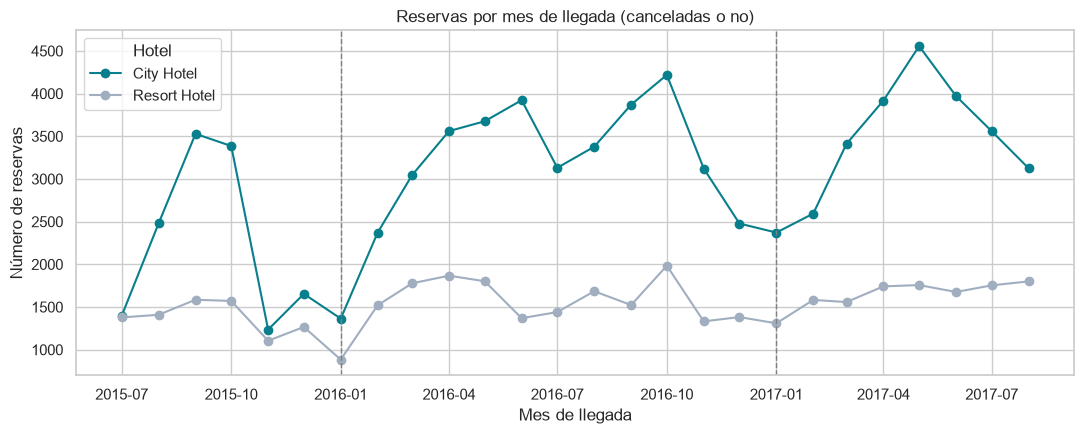

City Hotel: el mes con menos reservas es 2015-11 (1,235) y el de más es 2017-05 (4,556)
Resort Hotel: el mes con menos reservas es 2016-01 (884) y el de más es 2016-10 (1,984)


In [6]:
reservas_por_mes = (
    reservas.assign(mes=llegada.dt.to_period("M").dt.to_timestamp())
    .groupby(["hotel", "mes"])
    .size()
    .rename("reservas")
    .reset_index()
)

fig, ax = plt.subplots(figsize=(11, 4.5))
for hotel, datos in reservas_por_mes.groupby("hotel"):
    ax.plot(datos["mes"], datos["reservas"], marker="o", color=COLORES_HOTEL[hotel], label=hotel)
for anio in (2016, 2017):
    ax.axvline(pd.Timestamp(anio, 1, 1), color="gray", linestyle="--", linewidth=1)
ax.set_title("Reservas por mes de llegada (canceladas o no)")
ax.set_xlabel("Mes de llegada")
ax.set_ylabel("Número de reservas")
ax.legend(title="Hotel")
plt.tight_layout()
plt.show()

for hotel, datos in reservas_por_mes.groupby("hotel"):
    menor = datos.loc[datos["reservas"].idxmin()]
    mayor = datos.loc[datos["reservas"].idxmax()]
    print(f"{hotel}: el mes con menos reservas es {menor['mes']:%Y-%m} ({menor['reservas']:,}) "
          f"y el de más es {mayor['mes']:%Y-%m} ({mayor['reservas']:,})")

**¿Qué vemos?**

- El City Hotel no solo tiene más reservas, también cambia mucho más de un mes a otro: va de 1.235 reservas en noviembre de 2015 a 4.556 en mayo de 2017. Baja hacia diciembre y enero, y tiene sus picos en primavera (abril a junio) y en septiembre-octubre. El Resort Hotel se mueve en un rango más corto, entre 884 reservas (enero de 2016) y 1.984 (octubre de 2016).
- En julio y agosto de 2015 el City Hotel tiene bastantes menos reservas que en los mismos meses de 2016 y 2017. Con estos datos no sabemos si es que tenía menos demanda o si el registro arrancó incompleto, así que tampoco sacamos conclusiones de tendencia entre años.
- Como la demanda sube y baja tanto según el mes, es posible que el mes de llegada también pese en las cancelaciones. Eso no lo podemos concluir de esta gráfica, que cuenta todas las reservas juntas; lo miramos en la sección 3.

### 1.8 Cierre de la sección

- El problema es grande para estos dos hoteles: de 119.390 reservas se cancelaron 44.224, el 37,0 %.
- Los datos cubren 26 meses, pero solo 2016 está completo, y son de solo dos hoteles de Portugal. Lo que encontremos vale para ellos y no se puede generalizar sin más.
- Para predecir solo podemos usar lo que se sabe al momento de reservar, y el dataset trae columnas que se llenan después.

Antes de mirar las cancelaciones hay que revisar qué tan limpios vienen los datos, y eso es lo que hacemos en la sección 2.

## 2. Calidad de los datos

Antes de mirar las cancelaciones revisamos qué tan confiables vienen los datos. En esta sección solo hacemos el **diagnóstico**: no borramos ni cambiamos nada de `reservas`. Lo que proponemos al final lo aplica el notebook 02, dentro del preprocesamiento, para que todo lo que se ajuste con datos se aprenda solo con entrenamiento.

Revisamos, en este orden:

1. Valores faltantes y qué significa cada uno.
2. Tipos de datos y conversiones necesarias.
3. Filas duplicadas.
4. Valores imposibles o muy raros.
5. Atípicos de `lead_time`, `adr` y noches.
6. Variables categóricas de alta cardinalidad (`country`, `agent` y `company`).

Arriba dejamos las constantes de la sección. El total de noches y de huéspedes lo calculamos aparte, solo para el diagnóstico, sin agregarlo a `reservas`.

In [7]:
FACTOR_IQR = 1.5
TARIFA_MAXIMA_RAZONABLE = 1_000
TOPES_CATEGORIAS = (5, 10, 20)
MINIMO_RESERVAS_CATEGORIA = 100
COLUMNAS_ALTA_CARDINALIDAD = ["country", "agent", "company"]
COLUMNAS_CON_UNDEFINED = ["meal", "market_segment", "distribution_channel"]

total_noches = reservas["stays_in_weekend_nights"] + reservas["stays_in_week_nights"]
total_huespedes = reservas["adults"] + reservas["children"].fillna(0) + reservas["babies"]

### 2.1 Valores faltantes

Para cada columna con faltantes contamos cuántos hay y comparamos el porcentaje de cancelación de las reservas con el dato vacío contra las que sí lo tienen. Si las dos tasas son muy distintas, el faltante no es al azar: dice algo de la reserva.

In [8]:
def resumen_faltantes(datos):
    """Cantidad y porcentaje de faltantes por columna, y la cancelación con y sin el dato."""
    faltantes = datos.isna().sum()
    faltantes = faltantes[faltantes > 0].sort_values(ascending=False)
    filas = []
    for columna, cantidad in faltantes.items():
        vacio = datos[columna].isna()
        filas.append({
            "columna": columna,
            "faltantes": cantidad,
            "porcentaje": round(cantidad / len(datos) * 100, 2),
            "cancelacion_con_faltante_%": round(datos.loc[vacio, OBJETIVO].mean() * 100, 1),
            "cancelacion_con_dato_%": round(datos.loc[~vacio, OBJETIVO].mean() * 100, 1),
        })
    return pd.DataFrame(filas).set_index("columna")


resumen_faltantes(reservas)

,faltantes,porcentaje,cancelacion_con_faltante_%,cancelacion_con_dato_%
columna,,,,
company,112593,94.31,38.2,17.5
agent,16340,13.69,24.7,39.0
country,488,0.41,13.7,37.1
children,4,0.00,100.0,37.0


Para entender de dónde salen los faltantes de `agent` los cruzamos con el canal de distribución, y miramos en qué hotel quedaron las reservas sin país.

In [9]:
sin_agente = reservas["agent"].isna().map({True: "sin agente", False: "con agente"})
display(pd.crosstab(reservas["distribution_channel"], sin_agente, margins=True, margins_name="total"))

print("Reservas sin país, por hotel:")
print(reservas.loc[reservas["country"].isna(), "hotel"].value_counts().to_string())

agent,con agente,sin agente,total
distribution_channel,,,
Corporate,1134,5543,6677
Direct,7020,7625,14645
GDS,191,2,193
TA/TO,94703,3167,97870
Undefined,2,3,5
total,103050,16340,119390


Reservas sin país, por hotel:
hotel
Resort Hotel    464
City Hotel       24


Además de los vacíos, hay columnas de texto que traen el valor `Undefined`, que en la práctica también es un dato que no se registró.

In [10]:
for columna in COLUMNAS_CON_UNDEFINED:
    cantidad = (reservas[columna] == "Undefined").sum()
    print(f"{columna}: {cantidad:,} reservas con 'Undefined'")

meal: 1,169 reservas con 'Undefined'
market_segment: 2 reservas con 'Undefined'
distribution_channel: 5 reservas con 'Undefined'


**¿Qué vemos?**

- Solo cuatro columnas tienen vacíos y en ninguna parece un error de captura. Son faltantes **estructurales**: el campo queda vacío porque no aplica.
- `company` está vacía en 112.593 reservas (94,31 %). Lo normal es que la reserva no la haga ni la pague una empresa, así que el vacío quiere decir "no es de empresa". Las reservas con empresa cancelan mucho menos (17,5 % contra 38,2 %), y por eso no conviene borrar la columna sin más: lo que aporta es saber si hay empresa o no.
- `agent` falta en 16.340 reservas (13,69 %). Casi todas las reservas que llegan por agencias (*TA/TO*) tienen agente (94.703 de 97.870), mientras que en los canales *Direct* y *Corporate* la mayoría no lo tiene (7.625 de 14.645 y 5.543 de 6.677). O sea, el vacío casi siempre significa que la reserva se hizo sin agencia. Esas reservas cancelan menos (24,7 % contra 39,0 %).
- `country` falta en 488 reservas (0,41 %), casi todas del Resort Hotel (464). Cancelan 13,7 %, bastante menos que el 37,1 % de las que tienen país. Esto refuerza la duda que dejamos planteada en la sección 1.4: el país se puede estar llenando o corrigiendo cuando el cliente llega. Si es así, una reserva que nunca llegó tiene más probabilidad de quedarse sin país, y la variable estaría filtrando parte de la respuesta. Eso lo revisa con evidencia la sección 3.
- `children` solo falta en 4 reservas, todas del City Hotel en 2015 y todas canceladas. Son tan pocas que ponerles 0 no cambia nada.
- Los `Undefined` son pocos: 2 en `market_segment` y 5 en `distribution_channel`. En `meal` son 1.169; según el artículo original, `Undefined` y `SC` quieren decir lo mismo (sin plan de comidas), así que se pueden unir.

Lo que no permite concluir esta tabla: que las reservas sin agente o con empresa cancelen menos no quiere decir que el agente cause cancelaciones; puede ser el canal o el tipo de cliente que va detrás. Eso es asociación, no causa.

### 2.2 Tipos de datos

Miramos el tipo con el que pandas leyó cada columna, cuántos valores distintos tiene y un ejemplo de la primera fila.

In [11]:
tipos = pd.DataFrame({
    "tipo": reservas.dtypes.astype(str),
    "valores_distintos": reservas.nunique(),
    "ejemplo": reservas.iloc[0],
})
tipos

,tipo,valores_distintos,ejemplo
hotel,str,2,Resort Hotel
is_canceled,int64,2,0
lead_time,int64,479,342
arrival_date_year,int64,3,2015
arrival_date_month,str,12,July
arrival_date_week_number,int64,53,27
arrival_date_day_of_month,int64,31,1
stays_in_weekend_nights,int64,17,0
stays_in_week_nights,int64,35,0
adults,int64,14,2


In [12]:
print("Columnas decimales:", reservas.select_dtypes("float").columns.tolist())
print("Columnas de texto:", reservas.select_dtypes(exclude="number").columns.tolist())

Columnas decimales: ['children', 'agent', 'company', 'adr']
Columnas de texto: ['hotel', 'arrival_date_month', 'meal', 'country', 'market_segment', 'distribution_channel', 'reserved_room_type', 'assigned_room_type', 'deposit_type', 'customer_type', 'reservation_status', 'reservation_status_date']


**¿Qué vemos?**

Los tipos casi todos están bien, pero hay cuatro casos que toca resolver en el preprocesamiento:

- `children` quedó como decimal solo porque tiene 4 vacíos (pandas no guarda vacíos en columnas enteras). Después de ponerles 0 se puede volver entero.
- `agent` y `company` se leyeron como números decimales, pero son **códigos**: la agencia 240 no es "más" que la agencia 9. Si entran como números, un modelo lineal les daría un orden que no existe. Hay que tratarlas como categorías.
- `arrival_date_month` viene como texto en inglés. Para usarla como número o para ordenar por fecha hay que pasarla a número de mes, como ya hizo la función `fecha_de_llegada` de la sección 1.
- `reservation_status_date` es una fecha guardada como texto. No vale la pena convertirla porque no puede entrar al modelo: es la fecha del último estado, o sea, se conoce después.

Las variables `is_canceled` e `is_repeated_guest` son binarias (0 y 1) y ya vienen como enteros, que es lo que necesitamos.

### 2.3 Filas duplicadas

El dataset no trae un número de reserva, así que no hay forma de saber si dos filas idénticas son la misma reserva copiada dos veces o dos reservas distintas que coinciden en todo. Contamos cuántas hay y miramos cómo son.

In [13]:
duplicadas = reservas.duplicated()
con_alguna_copia = reservas.duplicated(keep=False)
veces_repetida = reservas.groupby(list(reservas.columns), dropna=False).size()
veces_repetida = veces_repetida[veces_repetida > 1]

print(f"Filas idénticas a otra que aparece antes: {duplicadas.sum():,} ({duplicadas.mean():.1%})")
print(f"Filas que tienen al menos una copia: {con_alguna_copia.sum():,} ({con_alguna_copia.mean():.1%})")
print(f"Combinaciones que se repiten: {len(veces_repetida):,}. "
      f"La mitad se repite {veces_repetida.median():.0f} veces y la que más, {veces_repetida.max()} veces")
print(f"Cancelación en las filas repetidas: {reservas.loc[duplicadas, OBJETIVO].mean():.1%}")
print(f"Cancelación si dejamos una sola fila por combinación: {reservas.loc[~duplicadas, OBJETIVO].mean():.1%}")

Filas idénticas a otra que aparece antes: 31,994 (26.8%)
Filas que tienen al menos una copia: 40,165 (33.6%)
Combinaciones que se repiten: 8,171. La mitad se repite 2 veces y la que más, 180 veces
Cancelación en las filas repetidas: 63.1%
Cancelación si dejamos una sola fila por combinación: 27.5%


In [14]:
def comparar_composicion(datos, mascara, columna, nombre):
    """Porcentaje de cada categoría dentro de las filas marcadas y en todo el dataset."""
    return pd.DataFrame({
        f"{nombre}_%": datos.loc[mascara, columna].value_counts(normalize=True).mul(100).round(1),
        "todas_%": datos[columna].value_counts(normalize=True).mul(100).round(1),
    }).fillna(0).sort_values(f"{nombre}_%", ascending=False)


display(comparar_composicion(reservas, duplicadas, "market_segment", "repetidas"))
display(comparar_composicion(reservas, duplicadas, "deposit_type", "repetidas"))

sin_reembolso = reservas["deposit_type"] == "Non Refund"
print(f"De las {sin_reembolso.sum():,} reservas 'Non Refund', el {duplicadas[sin_reembolso].mean():.1%} está repetida")

,repetidas_%,todas_%
market_segment,,
Groups,46.5,16.6
Offline TA/TO,32.3,20.3
Online TA,15.2,47.3
Corporate,3.4,4.4
Direct,2.5,10.6
Complementary,0.1,0.6
Aviation,0.0,0.2
Undefined,0.0,0.0


,repetidas_%,todas_%
deposit_type,,
No Deposit,57.5,87.6
Non Refund,42.3,12.2
Refundable,0.2,0.1


De las 14,587 reservas 'Non Refund', el 92.9% está repetida


**¿Qué vemos?**

- Hay 31.994 filas idénticas a otra (26,8 %), y si contamos también la primera aparición de cada una, 40.165 filas (33,6 %) tienen por lo menos una copia. La mayoría de las combinaciones se repiten 2 veces, pero hay una que aparece 180 veces.
- Las repetidas no se parecen al resto. El 46,5 % son del segmento *Groups*, que en todo el dataset es solo el 16,6 %, y el 42,3 % son *Non Refund*, contra 12,2 % en general. Eso cuadra con reservas de grupo: una agencia bloquea varias habitaciones iguales el mismo día, con la misma tarifa y las mismas fechas, y en el sistema quedan como filas idénticas. O sea, muchas de las "copias" pueden ser habitaciones reales distintas.
- Pesan mucho en la variable objetivo: las repetidas cancelan 63,1 %. Si dejamos una sola fila por combinación, la cancelación baja de 37,0 % a 27,5 %. Además, el 92,9 % de las reservas *Non Refund* está repetida; esto hay que tenerlo en cuenta en la sección 3 cuando se mire por qué ese tipo de depósito cancela tanto.

**Por qué son un problema al partir los datos.** Si partimos en entrenamiento y prueba al azar con las copias adentro, es casi seguro que una fila queda en entrenamiento y su gemela en prueba. El modelo "se aprende" esa fila y en prueba la acierta sin haber generalizado nada, así que las métricas salen mejores de lo que el modelo realmente es. Es una forma de fuga de información.

**Lo que no podemos saber.** Sin un número de reserva no hay manera de separar las copias por error de las habitaciones reales de un grupo. Cualquier decisión tiene un costo: si las quitamos, perdemos reservas reales y cambiamos la tasa de cancelación; si las dejamos, inflamos las métricas. Nuestra propuesta para el notebook 02 está en la tabla del cierre.

### 2.4 Valores imposibles o muy raros

Definimos reglas para lo que no puede pasar en una reserva real (una tarifa negativa, una reserva sin huéspedes) y para lo que es posible pero muy raro, y contamos cuántas filas cumplen cada una.

In [15]:
reglas = {
    "Tarifa (adr) negativa": ("imposible", reservas["adr"] < 0),
    f"Tarifa (adr) mayor a {TARIFA_MAXIMA_RAZONABLE:,}": ("imposible", reservas["adr"] > TARIFA_MAXIMA_RAZONABLE),
    "Cero huéspedes": ("imposible", total_huespedes == 0),
    "Cero noches": ("raro", total_noches == 0),
    "Niños o bebés sin ningún adulto": ("raro", (reservas["adults"] == 0) & (total_huespedes > 0)),
    "Nueve o más niños o bebés": ("raro", (reservas["children"] >= 9) | (reservas["babies"] >= 9)),
}

valores_raros = pd.DataFrame([
    {
        "regla": regla,
        "tipo": tipo,
        "reservas": mascara.sum(),
        "canceladas_%": round(reservas.loc[mascara, OBJETIVO].mean() * 100, 1),
        "tarifa_mediana": reservas.loc[mascara, "adr"].median(),
    }
    for regla, (tipo, mascara) in reglas.items()
]).set_index("regla")
valores_raros

,tipo,reservas,canceladas_%,tarifa_mediana
regla,,,,
Tarifa (adr) negativa,imposible,1,0.0,-6.38
"Tarifa (adr) mayor a 1,000",imposible,1,100.0,5400.00
Cero huéspedes,imposible,180,13.9,0.00
Cero noches,raro,715,4.9,0.00
Niños o bebés sin ningún adulto,raro,223,37.7,88.77
Nueve o más niños o bebés,raro,3,33.3,95.00


Miramos las filas de las dos tarifas imposibles y qué tarifas siguen después de la más alta.

In [16]:
columnas_detalle = ["hotel", "adr", "adults", "children", "stays_in_weekend_nights",
                    "stays_in_week_nights", "market_segment", "is_canceled"]
tarifa_imposible = reglas["Tarifa (adr) negativa"][1] | reglas[f"Tarifa (adr) mayor a {TARIFA_MAXIMA_RAZONABLE:,}"][1]
display(reservas.loc[tarifa_imposible, columnas_detalle])

print("Las tres tarifas más altas:", reservas["adr"].nlargest(3).tolist())

,hotel,adr,adults,children,stays_in_weekend_nights,stays_in_week_nights,market_segment,is_canceled
14969,Resort Hotel,-6.38,2,0.0,4,6,Groups,0
48515,City Hotel,5400.00,2,0.0,0,1,Offline TA/TO,1


Las tres tarifas más altas: [5400.0, 510.0, 508.0]


In [17]:
cero_noches = reglas["Cero noches"][1]
print("Reservas de cero noches por estado final:")
print(reservas.loc[cero_noches, "reservation_status"].value_counts().to_string())
print(f"Tarifa de esas reservas: mínima {reservas.loc[cero_noches, 'adr'].min()} y máxima {reservas.loc[cero_noches, 'adr'].max()}")
print(f"Reservas con cero noches y cero huéspedes a la vez: {(cero_noches & reglas['Cero huéspedes'][1]).sum()}")

Reservas de cero noches por estado final:
reservation_status
Check-Out    680
Canceled      22
No-Show       13
Tarifa de esas reservas: mínima 0.0 y máxima 0.0
Reservas con cero noches y cero huéspedes a la vez: 70


**¿Qué vemos?**

- **Tarifas.** Hay una tarifa negativa (−6,38) en una reserva de grupo del Resort Hotel de 10 noches que sí llegó; parece un ajuste contable mal registrado. La otra es de 5.400 por noche en el City Hotel, una noche para dos adultos y cancelada. Después de ella la tarifa más alta es 510, así que los 5.400 son casi seguro un error de digitación (le sobra un cero o más). Son solo dos filas, pero la de 5.400 sola desordena cualquier escala que use la media o la desviación estándar.
- **Cero huéspedes.** 180 reservas no tienen ni adultos, ni niños, ni bebés. No puede haber una reserva sin nadie, así que son registros incompletos.
- **Cero noches.** Son 715 y llama la atención que todas tienen tarifa 0 y que 680 terminaron en *Check-Out*. Pueden ser habitaciones de uso por el día o registros administrativos, pero no son estancias normales y no tienen tarifa que analizar. 70 de ellas además tienen cero huéspedes.
- **Niños sin adulto.** 223 reservas. Es raro, pero no imposible (puede ser un adulto que quedó registrado en otra reserva del mismo grupo).
- **Nueve o más niños o bebés.** Son 3 reservas con una tarifa mediana de 95, que es lo que cuesta una habitación normal. Nueve o diez niños o bebés en una habitación así es casi seguro un error de digitación.

En total son pocas filas frente a las 119.390, así que quitarlas no cambia la distribución general. Lo que sí no podemos asegurar es la causa de cada caso: estamos suponiendo errores de registro a partir de cómo se ven los datos, sin poder confirmarlo con el hotel.

### 2.5 Atípicos de anticipación, tarifa y noches

Usamos la regla del rango intercuartílico (IQR): un valor es atípico si queda más de 1,5 veces el IQR por debajo del primer cuartil o por encima del tercero. No quiere decir que esté mal; solo que se sale de lo común. Por eso, además de contarlos, miramos a qué reservas corresponden.

In [18]:
def limites_iqr(serie, factor=FACTOR_IQR):
    """Límites inferior y superior de la regla del rango intercuartílico."""
    q1, q3 = serie.quantile([0.25, 0.75])
    rango = q3 - q1
    return q1 - factor * rango, q3 + factor * rango


variables_atipicos = {
    "lead_time": reservas["lead_time"],
    "adr": reservas["adr"],
    "noches": total_noches,
}

atipicos = {}
filas = []
for nombre, serie in variables_atipicos.items():
    inferior, superior = limites_iqr(serie)
    atipico = (serie < inferior) | (serie > superior)
    atipicos[nombre] = atipico
    filas.append({
        "variable": nombre,
        "mediana": serie.median(),
        "limite_inferior": round(inferior, 2),
        "limite_superior": round(superior, 2),
        "maximo": serie.max(),
        "atipicos": atipico.sum(),
        "atipicos_%": round(atipico.mean() * 100, 2),
        "cancelacion_atipicos_%": round(reservas.loc[atipico, OBJETIVO].mean() * 100, 1),
        "cancelacion_resto_%": round(reservas.loc[~atipico, OBJETIVO].mean() * 100, 1),
    })
pd.DataFrame(filas).set_index("variable")

,mediana,limite_inferior,limite_superior,maximo,atipicos,atipicos_%,cancelacion_atipicos_%,cancelacion_resto_%
variable,,,,,,,,
lead_time,69.000,-195.00,373.00,737.0,3005,2.52,66.7,36.3
adr,94.575,-15.77,211.06,5400.0,3793,3.18,38.7,37.0
noches,3.000,-1.00,7.00,69.0,5257,4.40,35.7,37.1


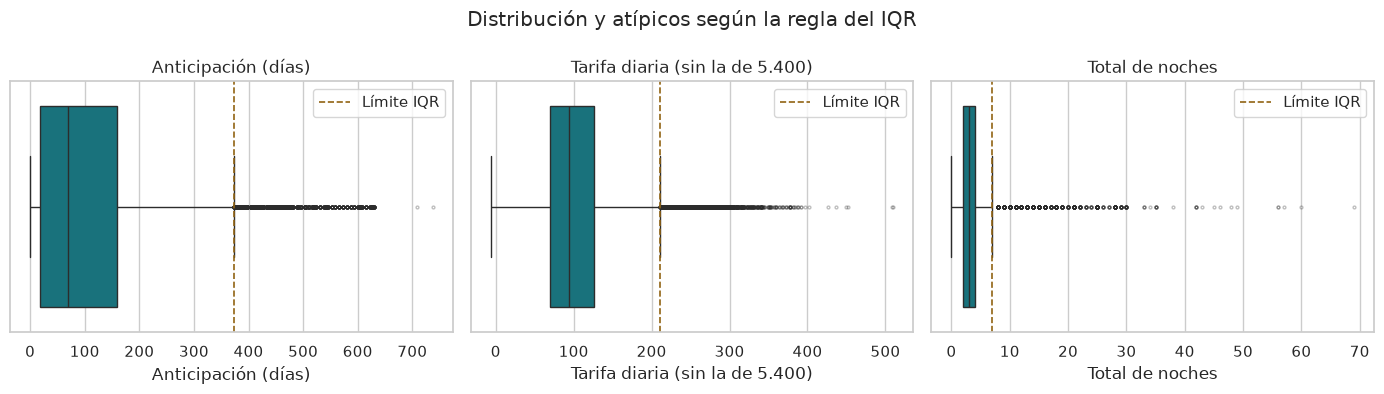

In [19]:
etiquetas = {
    "lead_time": "Anticipación (días)",
    "adr": "Tarifa diaria (sin la de 5.400)",
    "noches": "Total de noches",
}

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (nombre, serie) in zip(axes, variables_atipicos.items()):
    if nombre == "adr":
        serie = serie[serie <= TARIFA_MAXIMA_RAZONABLE]
    _, superior = limites_iqr(variables_atipicos[nombre])
    sns.boxplot(x=serie, ax=ax, color=COLOR_PRINCIPAL,
                flierprops={"markersize": 2, "alpha": 0.3})
    ax.axvline(superior, color=COLOR_RIESGO, linestyle="--", linewidth=1.2, label="Límite IQR")
    ax.set_title(etiquetas[nombre])
    ax.set_xlabel(etiquetas[nombre])
    ax.legend(loc="upper right")
fig.suptitle("Distribución y atípicos según la regla del IQR")
plt.tight_layout()
plt.show()

Para ver a qué reservas corresponden los atípicos, comparamos su perfil con el de todas las reservas.

In [20]:
def perfil(mascara):
    """Resume segmento, hotel, mes, repetidas y huéspedes de las reservas marcadas."""
    seleccion = reservas[mascara]
    return {
        "reservas": int(mascara.sum()),
        "% Groups": round((seleccion["market_segment"] == "Groups").mean() * 100, 1),
        "% Online TA": round((seleccion["market_segment"] == "Online TA").mean() * 100, 1),
        "% Resort Hotel": round((seleccion["hotel"] == "Resort Hotel").mean() * 100, 1),
        "% llegada en julio o agosto": round(seleccion["arrival_date_month"].isin(["July", "August"]).mean() * 100, 1),
        "% filas repetidas": round(duplicadas[mascara].mean() * 100, 1),
        "mediana de huéspedes": total_huespedes[mascara].median(),
    }


todas = pd.Series(True, index=reservas.index)
perfiles = {f"atípicos de {nombre}": perfil(mascara) for nombre, mascara in atipicos.items()}
perfiles["todas las reservas"] = perfil(todas)
pd.DataFrame.from_dict(perfiles, orient="index")

,reservas,% Groups,% Online TA,% Resort Hotel,% llegada en julio o agosto,% filas repetidas,mediana de huéspedes
atípicos de lead_time,3005,67.3,0.3,14.3,29.7,82.1,2.0
atípicos de adr,3793,2.6,70.9,66.0,73.5,4.5,3.0
atípicos de noches,5257,5.6,46.4,76.3,36.5,7.5,2.0
todas las reservas,119390,16.6,47.3,33.6,22.2,26.8,2.0


**¿Qué vemos?**

- **`lead_time`.** Desde 373 días de anticipación una reserva es atípica, y hay 3.005 (2,52 %), con un máximo de 737 días. No parecen errores: el 67,3 % son del segmento *Groups* y el 82,1 % son filas repetidas, o sea, bloqueos de habitaciones que las agencias hacen con más de un año de anticipación. Cancelan 66,7 %, casi el doble que el resto (36,3 %). Quitarlas sería botar justo un tipo de reserva que cancela mucho.
- **`adr`.** Por encima de 211,06 hay 3.793 tarifas atípicas (3,18 %). El 73,5 % llega en julio o agosto, el 66,0 % es del Resort Hotel y la mediana es de 3 huéspedes: son habitaciones grandes en temporada alta en la playa, que es normal que sean caras. Cancelan casi igual que el resto (38,7 % contra 37,0 %). La excepción es la tarifa de 5.400, que ya vimos que es un error. La tarifa negativa no sale como atípica porque el límite inferior es −15,77.
- **Noches.** Desde 8 noches una estancia es atípica: 5.257 reservas (4,40 %), con un máximo de 69 noches. El 76,3 % son del Resort Hotel, que es lo esperable para vacaciones de playa. Tampoco cambian la cancelación (35,7 % contra 37,1 %).
- En los tres casos el límite inferior queda negativo, así que la regla solo marca valores altos.

En general, los atípicos de estas tres variables son reservas reales con un comportamiento distinto, no errores, y tienen información útil. Lo que sí hacen es estirar mucho las distribuciones hacia la derecha, y eso afecta a los métodos que dependen de distancias o de la media, como K-Means o el escalado estándar.

### 2.6 Variables de alta cardinalidad

`country`, `agent` y `company` tienen muchas categorías. Para cada una contamos cuántas hay, qué porcentaje de las reservas (con dato) acumulan las más frecuentes y cuántas categorías tienen muy pocas reservas.

In [21]:
def resumen_cardinalidad(serie):
    """Cuántas categorías hay, cuánto acumulan las más frecuentes y cuántas son raras."""
    conteo = serie.value_counts()
    acumulado = conteo.cumsum() / conteo.sum() * 100
    resumen = {"categorias": len(conteo), "reservas_con_dato": conteo.sum()}
    for tope in TOPES_CATEGORIAS:
        resumen[f"top_{tope}_%"] = round(acumulado.iloc[tope - 1], 1)
    resumen["categorias_para_el_90_%"] = int((acumulado < 90).sum() + 1)
    resumen[f"con_menos_de_{MINIMO_RESERVAS_CATEGORIA}"] = int((conteo < MINIMO_RESERVAS_CATEGORIA).sum())
    resumen["con_una_sola_reserva"] = int((conteo == 1).sum())
    codigo = conteo.index[0]
    resumen["mas_frecuente"] = int(codigo) if isinstance(codigo, float) else codigo
    resumen["mas_frecuente_%"] = round(conteo.iloc[0] / conteo.sum() * 100, 1)
    return resumen


cardinalidad = pd.DataFrame.from_dict(
    {columna: resumen_cardinalidad(reservas[columna]) for columna in COLUMNAS_ALTA_CARDINALIDAD},
    orient="index",
)
cardinalidad

,categorias,reservas_con_dato,top_5_%,top_10_%,top_20_%,categorias_para_el_90_%,con_menos_de_100,con_una_sola_reserva,mas_frecuente,mas_frecuente_%
country,177,118902,73.2,84.8,94.2,14,139,30,PRT,40.9
agent,333,103050,58.5,69.2,78.3,52,249,50,9,31.0
company,352,6797,35.9,45.9,56.9,122,341,80,40,13.6


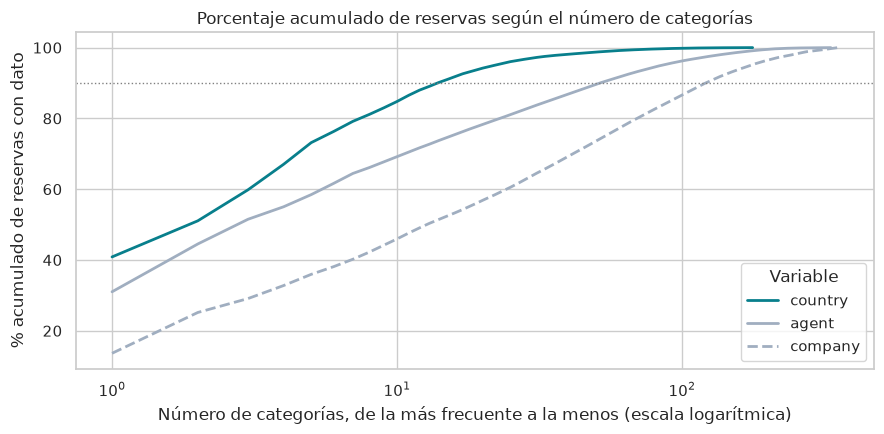

Si las tres entraran completas con one-hot serían 862 columnas nuevas


In [22]:
estilos = {
    "country": {"color": COLOR_PRINCIPAL, "linestyle": "-"},
    "agent": {"color": COLOR_SECUNDARIO, "linestyle": "-"},
    "company": {"color": COLOR_SECUNDARIO, "linestyle": "--"},
}

fig, ax = plt.subplots(figsize=(9, 4.5))
for columna in COLUMNAS_ALTA_CARDINALIDAD:
    conteo = reservas[columna].value_counts()
    acumulado = conteo.cumsum() / conteo.sum() * 100
    ax.plot(range(1, len(conteo) + 1), acumulado.values, label=columna, linewidth=2, **estilos[columna])
ax.axhline(90, color="gray", linestyle=":", linewidth=1)
ax.set_xscale("log")
ax.set_title("Porcentaje acumulado de reservas según el número de categorías")
ax.set_xlabel("Número de categorías, de la más frecuente a la menos (escala logarítmica)")
ax.set_ylabel("% acumulado de reservas con dato")
ax.legend(title="Variable")
plt.tight_layout()
plt.show()

print(f"Si las tres entraran completas con one-hot serían {cardinalidad['categorias'].sum()} columnas nuevas")

**¿Qué vemos?**

- **`country`** tiene 177 países, pero 14 ya acumulan el 90 % de las reservas y uno solo, Portugal (`PRT`), tiene el 40,9 %. 139 países tienen menos de 100 reservas y 30 tienen una sola.
- **`agent`** tiene 333 agencias. La agencia 9 sola tiene el 31,0 % de las reservas con agente, pero la cola es larga: hacen falta 52 agencias para llegar al 90 % y 249 tienen menos de 100 reservas.
- **`company`** es la más dispersa: 352 empresas repartidas en solo 6.797 reservas. La más frecuente no llega al 14 %, se necesitan 122 empresas para el 90 % y 341 tienen menos de 100 reservas.
- Si las tres entraran completas con *one-hot* tendríamos 862 columnas nuevas, la mayoría casi vacías. Con una categoría que tiene una o dos reservas, el modelo no puede aprender nada que generalice; lo que aprende es ruido. Además, una categoría que solo aparece en prueba no tendría columna.

En la gráfica se ve la diferencia: la línea de `country` sube muy rápido (pocas categorías explican casi todo), la de `agent` sube a un ritmo medio y la de `company` va subiendo despacio porque está muy repartida.

Lo que no podemos decir todavía es si estas variables sirven para predecir. Eso depende de la sección 3, sobre todo para `country`, que puede tener fuga.

### 2.7 Cierre de la sección: problemas encontrados y tratamiento propuesto

| Problema | Qué encontramos | Tratamiento que proponemos para el notebook 02 |
|---|---|---|
| Faltantes en `company` | 112.593 (94,31 %). Vacío = la reserva no es de empresa | No usar el código. Crear el indicador `tiene_empresa` (1 si tiene dato, 0 si no) |
| Faltantes en `agent` | 16.340 (13,69 %), casi todos en los canales *Direct* y *Corporate* | Llenarlos con la categoría "Sin agente" |
| Faltantes en `country` | 488 (0,41 %), cancelan 13,7 % | Llenarlos con "Desconocido", si la sección 3 decide que `country` entra |
| Faltantes en `children` | 4 reservas | Llenarlos con 0 y volver la columna entera |
| `Undefined` en `meal` | 1.169, equivale a `SC` (sin plan) | Unir `Undefined` con `SC` |
| `Undefined` en `market_segment` y `distribution_channel` | 2 y 5 reservas | Dejarlas; la codificación las agrupa con las categorías raras |
| `agent` y `company` leídas como números | Son códigos, no cantidades | Tratar `agent` como categórica |
| `arrival_date_month` como texto | Mes en inglés | Pasarla a número de mes |
| Duplicados | 31.994 filas (26,8 %); cancelan 63,1 %; sobre todo *Groups* y *Non Refund* | Dejar una sola fila por combinación **antes** de partir en entrenamiento y prueba, para que una misma fila no quede en los dos lados. Tener presente que la cancelación baja a 27,5 % y reportarlo |
| Tarifas imposibles | Una de −6,38 y una de 5.400 | Quitar las dos filas |
| Cero huéspedes | 180 reservas | Quitarlas |
| Cero noches | 715 reservas, todas con tarifa 0 | Quitarlas, porque no son estancias |
| Nueve o más niños o bebés | 3 reservas | Quitarlas |
| Niños sin adulto | 223 reservas | Dejarlas; son raras pero posibles |
| Atípicos de `lead_time`, `adr` y noches | 2,52 %, 3,18 % y 4,40 % de las reservas; son reservas reales | No quitarlos. Tenerlos en cuenta al escalar y en K-Means (por ejemplo, con una transformación logarítmica) |
| Alta cardinalidad de `country` y `agent` | 177 y 333 categorías; muchas con menos de 100 reservas | *One-hot* que agrupe las categorías poco frecuentes en "otras", ajustado solo con entrenamiento |

Todo lo que dependa de los datos, como qué categorías son frecuentes, se tiene que calcular solo con entrenamiento. Por eso lo dejamos como propuesta y no lo aplicamos aquí. Las filas que se quitan por reglas fijas (tarifas imposibles, cero huéspedes) sí se pueden quitar antes de partir, porque la regla no aprende nada de los datos.

Lo que sigue es mirar las cancelaciones: cómo se distribuyen, con qué variables se relacionan y cuáles hay que dejar por fuera por fuga de información. Eso es la sección 3.

## 3. Análisis exploratorio de las cancelaciones

Ya sabemos cómo vienen los datos. Ahora sí miramos las cancelaciones: qué tan desbalanceada está la variable objetivo, con qué características de la reserva se relaciona y qué columnas no podemos usar porque se conocen después de reservar.

Hay algo de la sección 2 que condiciona todo lo que sigue. Las filas repetidas cancelan 63,1 % y en la tabla de la 2.7 propusimos dejar una sola fila por combinación antes de partir los datos. Si miramos las tasas solo con todas las filas, estamos describiendo unos datos distintos a los que va a ver el modelo. Y si las miramos solo sin duplicados, se nos olvida que muchas de esas copias pueden ser habitaciones reales de un grupo. Por eso sacamos cada tasa de las dos formas y las ponemos lado a lado. Cuando las dos cuentan lo mismo, el hallazgo es firme; cuando no, lo decimos.

Esto sigue siendo diagnóstico: `reservas` no cambia y `reservas_unicas` es solo el filtro de las filas que no repiten a otra anterior. Además, estas tasas son para entender los datos y ninguna entra al modelo. Y cuando decidimos si una columna tiene fuga, miramos en qué momento se conoce, no cuánto ayudaría a predecir.

El orden de la sección:

1. Desbalance de `is_canceled` y por qué no basta con el accuracy.
2. Hotel y anticipación.
3. Tipo de depósito.
4. Segmento, canal y tipo de cliente.
5. Mes de llegada.
6. Cancelaciones previas, pedidos especiales y parqueadero.
7. Correlaciones.
8. Variables con fuga de información.
9. Qué pasa con los duplicados cuando salen esas columnas.

In [23]:
import numpy as np
from matplotlib.colors import LinearSegmentedColormap

reservas_unicas = reservas[~duplicadas]

BASES = {"Todas las filas": reservas, "Sin duplicados": reservas_unicas}
COLUMNAS_TASA = {"cancelacion_todas_%": "Todas las filas", "cancelacion_unicas_%": "Sin duplicados"}
COLORES_BASE = [COLOR_SECUNDARIO, COLOR_PRINCIPAL]
TASA_UNICAS = reservas_unicas[OBJETIVO].mean() * 100

MINIMO_FILAS_GRAFICA = 30
MINIMO_FILAS_SEGMENTO = 500
TOPE_CONTEOS = 3
CORTES_ANTICIPACION = [-1, 7, 30, 90, 180, 365, reservas["lead_time"].max()]
ETIQUETAS_ANTICIPACION = ["0 a 7", "8 a 30", "31 a 90", "91 a 180", "181 a 365", "Más de 365"]
CORTES_ESPERA = [-1, 0, 30, 60, 100, reservas["days_in_waiting_list"].max()]
ETIQUETAS_ESPERA = ["0", "1 a 30", "31 a 60", "61 a 100", "Más de 100"]
MESES_COMPARABLES = ["July", "August"]
SEGMENTOS_COMPARAR = ["Online TA", "Offline TA/TO", "Groups"]
PAISES_COMPARAR = ["PRT", "GBR", "FRA", "ESP", "DEU"]
FECHAS_MAS_FRECUENTES = 10


def tasas_de_cancelacion(grupos):
    """Filas y % de cancelación por grupo, con todas las filas y sin duplicados."""
    tablas = []
    for sufijo, base in (("todas", reservas), ("unicas", reservas_unicas)):
        filas = base.index.intersection(grupos.index)
        agrupadas = base.loc[filas, OBJETIVO].groupby(grupos.loc[filas], observed=True)
        tablas.append(pd.DataFrame({
            f"filas_{sufijo}": agrupadas.size(),
            f"cancelacion_{sufijo}_%": agrupadas.mean().mul(100).round(1),
        }))
    tabla = pd.concat(tablas, axis=1)
    tabla["cambio_en_puntos"] = (tabla["cancelacion_unicas_%"] - tabla["cancelacion_todas_%"]).round(1)
    return tabla


def graficar_tasas(tabla, titulo, etiqueta_grupo, ax):
    """Barras con el % de cancelación de cada grupo en las dos bases."""
    visibles = tabla[tabla["filas_todas"] >= MINIMO_FILAS_GRAFICA]
    visibles[list(COLUMNAS_TASA)].rename(columns=COLUMNAS_TASA).plot.bar(
        ax=ax, color=COLORES_BASE, width=0.8, edgecolor="white")
    for barras in ax.containers:
        ax.bar_label(barras, fmt="%.1f", fontsize=8, padding=2)
    ax.axhline(TASA_UNICAS, color=COLOR_RIESGO, linestyle="--", linewidth=1.2,
               label=f"Promedio sin duplicados ({TASA_UNICAS:.1f} %)")
    ax.set_ylim(0, visibles[list(COLUMNAS_TASA)].max().max() * 1.15)
    ax.grid(axis="x", visible=False)
    ax.set_title(titulo)
    ax.set_xlabel(etiqueta_grupo)
    ax.set_ylabel("% de reservas canceladas")
    ax.tick_params(axis="x", rotation=0)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncols=3, frameon=False)


def mostrar_tasas(grupos, titulo, etiqueta_grupo, ordenar=True, ancho=8):
    """Muestra la tabla y la gráfica de cancelación de una variable y devuelve la tabla."""
    tabla = tasas_de_cancelacion(grupos)
    if ordenar:
        tabla = tabla.sort_values("cancelacion_unicas_%", ascending=False)
    display(tabla)
    fig, ax = plt.subplots(figsize=(ancho, 4.5))
    graficar_tasas(tabla, titulo, etiqueta_grupo, ax)
    plt.tight_layout()
    plt.show()
    return tabla


def agrupar_conteo(serie):
    """Deja los conteos hasta el tope y junta los demás en un solo grupo."""
    return serie.clip(upper=TOPE_CONTEOS).astype(str).replace(str(TOPE_CONTEOS), f"{TOPE_CONTEOS} o más")

### 3.1 Qué tan desbalanceada está `is_canceled`

Contamos canceladas y no canceladas en las dos bases, y calculamos el accuracy que sacaría un modelo que no aprende nada y siempre dice que la reserva no se cancela.

,filas,canceladas,no_canceladas,cancelacion_%,no_canceladas_por_cada_cancelada,accuracy_sin_aprender_nada_%
Todas las filas,119390,44224,75166,37.0,1.70,63.0
Sin duplicados,87396,24025,63371,27.5,2.64,72.5


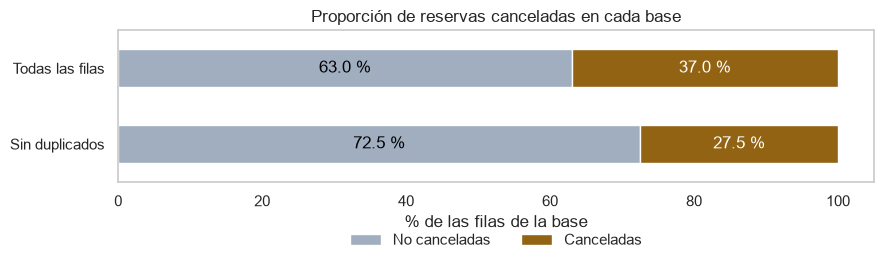

In [24]:
def resumen_objetivo(base):
    """Tamaño de las clases y accuracy de un modelo que nunca predice cancelación."""
    positivas = base[OBJETIVO].sum()
    negativas = len(base) - positivas
    return {
        "filas": len(base),
        "canceladas": positivas,
        "no_canceladas": negativas,
        "cancelacion_%": round(positivas / len(base) * 100, 1),
        "no_canceladas_por_cada_cancelada": round(negativas / positivas, 2),
        "accuracy_sin_aprender_nada_%": round(negativas / len(base) * 100, 1),
    }


objetivo_por_base = pd.DataFrame.from_dict(
    {nombre: resumen_objetivo(base) for nombre, base in BASES.items()}, orient="index"
)
display(objetivo_por_base)

clases = pd.DataFrame({
    "No canceladas": 100 - objetivo_por_base["cancelacion_%"],
    "Canceladas": objetivo_por_base["cancelacion_%"],
})
fig, ax = plt.subplots(figsize=(9, 3))
clases.plot.barh(stacked=True, ax=ax, color=[COLOR_SECUNDARIO, COLOR_RIESGO], edgecolor="white")
for barras, color_texto in zip(ax.containers, ["black", "white"]):
    ax.bar_label(barras, fmt="%.1f %%", label_type="center", color=color_texto)
ax.invert_yaxis()
ax.grid(False)
ax.set_title("Proporción de reservas canceladas en cada base")
ax.set_xlabel("% de las filas de la base")
ax.set_ylabel("")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.25), ncols=2, frameon=False)
plt.tight_layout()
plt.show()

**¿Qué vemos?**

Con todas las filas cancela el 37,0 % y sin duplicados el 27,5 %. En los dos casos el desbalance es moderado: hay 1,70 no canceladas por cada cancelada en el primero y 2,64 en el segundo. Quitar las copias lo vuelve un poco más desbalanceado, y eso hay que tenerlo presente al decidir `class_weight` en el notebook 03.

Con este desbalance el accuracy no nos sirve solo. Un modelo que siempre diga "no se cancela" saca 63,0 % con todas las filas y 72,5 % sin duplicados, y no detecta ni una cancelación, que es justo lo que le interesa al hotel. Ojo además con que ese piso sube 9,5 puntos solo por quitar las copias: un accuracy de 75 % se vería decente en la primera base y casi no le ganaría al modelo tonto en la segunda. Por eso evaluamos con Recall, Precision, F1 y ROC-AUC, como pide el enunciado. La PR-AUC de apoyo también depende de la base, porque un modelo al azar saca más o menos la proporción de positivos (0,37 o 0,275). Así que los resultados con y sin duplicados no se pueden comparar de forma directa.

Lo que esto no permite concluir es que la tasa "verdadera" del hotel sea 27,5 %. Si muchas de las copias son habitaciones reales de un grupo, lo que el hotel pierde está más cerca del 37,0 %. Para entrenar nos sirve quitar las copias, pero cuando en el notebook 05 hablemos de plata perdida toca tener presente el otro número.

### 3.2 Hotel y anticipación

Empezamos por dos variables que se conocen desde que entra la reserva: en qué hotel es y con cuántos días de anticipación se hace.

,filas_todas,cancelacion_todas_%,filas_unicas,cancelacion_unicas_%,cambio_en_puntos
hotel,,,,,
City Hotel,79330,41.7,53428,30.0,-11.7
Resort Hotel,40060,27.8,33968,23.5,-4.3


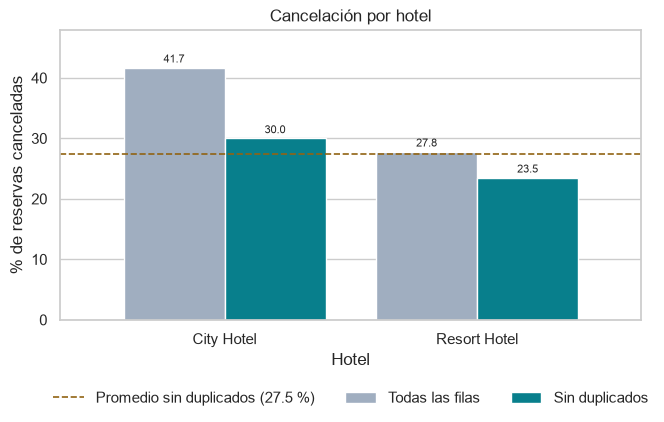

In [25]:
por_hotel = mostrar_tasas(reservas["hotel"], "Cancelación por hotel", "Hotel", ancho=7)

**¿Qué vemos?**

El City Hotel cancela más en las dos bases, pero la diferencia se encoge bastante: con todas las filas es 41,7 % contra 27,8 % (13,9 puntos) y sin duplicados es 30,0 % contra 23,5 % (6,5 puntos). O sea que más de la mitad de la brecha venía de las copias, que se concentran en el City Hotel: pierde 25.902 filas al quitarlas y el Resort Hotel 6.092.

Sigue habiendo diferencia, pero con esto no podemos decir que sea por ser un hotel de ciudad. Son solo dos hoteles, y detrás pueden estar otros clientes y otros canales. Tampoco se puede pasar a otros hoteles de ciudad o de playa.

,filas_todas,cancelacion_todas_%,filas_unicas,cancelacion_unicas_%,cambio_en_puntos
lead_time,,,,,
0 a 7,19746,9.6,18304,8.4,-1.2
8 a 30,18960,27.9,16340,25.4,-2.5
31 a 90,29553,37.7,22744,32.0,-5.7
91 a 180,26439,44.7,18243,35.0,-9.7
181 a 365,21544,55.5,11200,39.7,-15.8
Más de 365,3148,67.7,565,40.9,-26.8


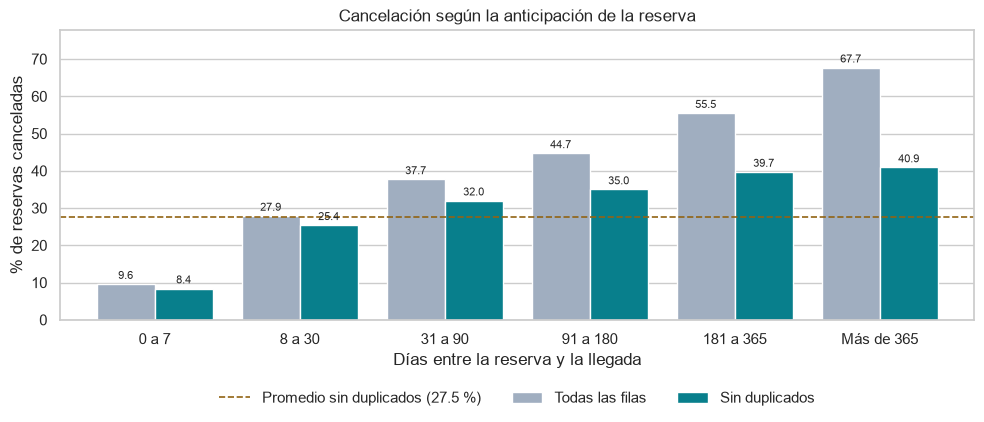

Todas las filas: mediana de 113 días en las canceladas y 45 en las no canceladas
Sin duplicados: mediana de 80 días en las canceladas y 38 en las no canceladas


In [26]:
anticipacion = pd.cut(reservas["lead_time"], bins=CORTES_ANTICIPACION, labels=ETIQUETAS_ANTICIPACION)
por_anticipacion = mostrar_tasas(anticipacion, "Cancelación según la anticipación de la reserva",
                                 "Días entre la reserva y la llegada", ordenar=False, ancho=10)

for nombre, base in BASES.items():
    medianas = base.groupby(OBJETIVO)["lead_time"].median()
    print(f"{nombre}: mediana de {medianas[1]:.0f} días en las canceladas y {medianas[0]:.0f} en las no canceladas")

**¿Qué vemos?**

Este hallazgo aguanta en las dos bases: entre más anticipación, más cancelación. Las reservas de la última semana casi no se cancelan (9,6 % y 8,4 %), y la mediana de anticipación de las canceladas es más o menos el doble de la de las no canceladas (113 contra 45 días con todas las filas, 80 contra 38 sin duplicados).

Lo que cambia es la parte alta. Con todas las filas la tasa sigue subiendo hasta 67,7 % en las de más de un año, pero esas 3.148 filas quedan en 565 al quitar las copias y la tasa baja a 40,9 %. Sin duplicados la curva sube rápido en el primer mes, de 8,4 % a 25,4 %, y después se va aplanando (39,7 % y 40,9 % en los dos últimos grupos). Como la relación no es una línea recta, a un modelo lineal le puede servir una transformación de `lead_time`, como ya se había dicho en la sección 2.

`lead_time` se conoce al reservar, así que cumple la regla. La lectura más natural es que con más tiempo hay más oportunidad de que a uno le cambien los planes, pero eso es una suposición nuestra: los datos muestran la asociación y no el motivo.

### 3.3 Tipo de depósito

Esta es la variable donde más pesan los duplicados, porque el 92,9 % de las reservas *Non Refund* está repetida. Primero miramos las tasas y después cuánto de la baja de 37,0 % a 27,5 % viene de ahí.

,filas_todas,cancelacion_todas_%,filas_unicas,cancelacion_unicas_%,cambio_en_puntos
deposit_type,,,,,
Non Refund,14587,99.4,1038,94.7,-4.7
No Deposit,104641,28.4,86251,26.7,-1.7
Refundable,162,22.2,107,24.3,2.1


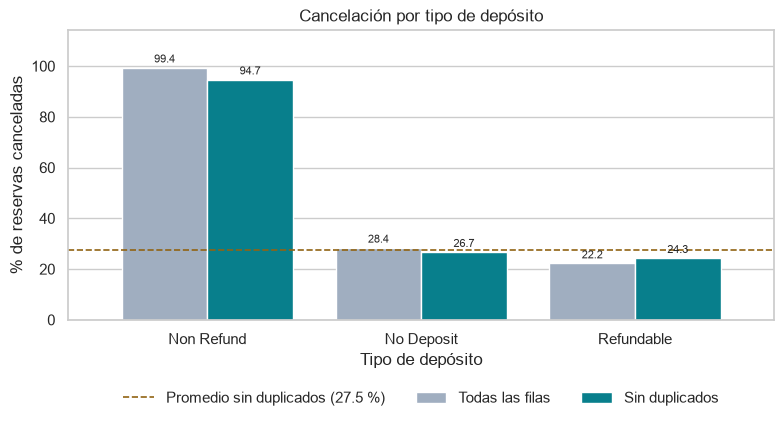

Todas las filas: Non Refund son 14,587 filas (12.2%) y sin ellas la cancelación es 28.4%
Sin duplicados: Non Refund son 1,038 filas (1.2%) y sin ellas la cancelación es 26.7%


In [27]:
por_deposito = mostrar_tasas(reservas["deposit_type"], "Cancelación por tipo de depósito", "Tipo de depósito", ancho=8)

for nombre, base in BASES.items():
    es_non_refund = base["deposit_type"] == "Non Refund"
    print(f"{nombre}: Non Refund son {es_non_refund.sum():,} filas ({es_non_refund.mean():.1%}) "
          f"y sin ellas la cancelación es {base.loc[~es_non_refund, OBJETIVO].mean():.1%}")

**¿Qué vemos?**

*Non Refund* cancela 99,4 % con todas las filas y 94,7 % sin duplicados, o sea que la tasa altísima sigue ahí aunque quitemos las copias. Lo que cambia es cuánto pesa: pasa de 14.587 filas (12,2 %) a 1.038 (1,2 %). Y eso explica casi toda la baja de la cancelación general. Si sacamos *Non Refund*, la tasa con todas las filas ya es 28,4 %, y de ahí a 26,7 % sin duplicados hay poca distancia. De los 9,5 puntos que baja, 8,6 salen de este solo tipo de depósito.

*No Deposit* casi no se mueve (28,4 % y 26,7 %). *Refundable* tiene muy pocas filas (162 y 107), así que su tasa no nos dice mucho.

Lo que sigue siendo raro es que alguien cancele casi siempre cuando no le devuelven la plata. Para entenderlo miramos cómo son esas reservas y cuándo se cancelaron.

In [28]:
def perfil_deposito(base):
    """Canal, país, anticipación y pedidos de un grupo de reservas."""
    return {
        "filas": len(base),
        "% Groups u Offline TA/TO": round(base["market_segment"].isin(["Groups", "Offline TA/TO"]).mean() * 100, 1),
        "% Portugal": round((base["country"] == "PRT").mean() * 100, 1),
        "mediana de lead_time": base["lead_time"].median(),
        "% con pedidos especiales": round((base["total_of_special_requests"] > 0).mean() * 100, 1),
    }


es_non_refund_unica = reservas_unicas["deposit_type"] == "Non Refund"
display(pd.DataFrame.from_dict({
    "Non Refund, todas las filas": perfil_deposito(reservas[sin_reembolso]),
    "Non Refund, sin duplicados": perfil_deposito(reservas_unicas[es_non_refund_unica]),
    "Otros depósitos, sin duplicados": perfil_deposito(reservas_unicas[~es_non_refund_unica]),
}, orient="index"))

todas_canceladas = reservas[OBJETIVO] == 1
for nombre, mascara in (("Non Refund", sin_reembolso), ("Otros depósitos", ~sin_reembolso)):
    fechas = reservas.loc[todas_canceladas & mascara, "reservation_status_date"].value_counts()
    concentracion = fechas.head(FECHAS_MAS_FRECUENTES).sum() / fechas.sum()
    print(f"{nombre}: {fechas.sum():,} cancelaciones en {len(fechas)} fechas. "
          f"Las {FECHAS_MAS_FRECUENTES} fechas con más cancelaciones tienen el {concentracion:.1%}. "
          f"La que más: {fechas.index[0]} con {fechas.iloc[0]:,}")

,filas,% Groups u Offline TA/TO,% Portugal,mediana de lead_time,% con pedidos especiales
"Non Refund, todas las filas",14587,97.2,97.2,183.0,0.2
"Non Refund, sin duplicados",1038,91.1,94.7,188.5,1.4
"Otros depósitos, sin duplicados",86358,20.7,30.7,48.0,50.4


Non Refund: 14,494 cancelaciones en 262 fechas. Las 10 fechas con más cancelaciones tienen el 34.7%. La que más: 2015-10-21 con 1,357
Otros depósitos: 29,730 cancelaciones en 900 fechas. Las 10 fechas con más cancelaciones tienen el 5.7%. La que más: 2015-07-06 con 423


**¿Qué vemos?**

Estas reservas no se parecen a un huésped suelto que perdió su depósito. El 97,2 % llega por *Groups* u *Offline TA/TO* (91,1 % sin duplicados), el 97,2 % está registrado como Portugal (94,7 %), la anticipación mediana es de 183 días contra 48 del resto de reservas, y casi ninguna tiene pedidos especiales (0,2 % y 1,4 %, contra 50,4 % en los otros depósitos).

También se cancelan en bloque. Las 10 fechas con más cancelaciones tienen el 34,7 % de las de *Non Refund* y solo el 5,7 % de las de otros depósitos, y en una sola fecha, el 21 de octubre de 2015, se cancelaron 1.357. Esto toca mirarlo con todas las filas, porque son justamente esas filas iguales las que desaparecen al quitar duplicados. Cuadra con una agencia que bloquea muchas habitaciones con meses de anticipación y las suelta de una, que además es la explicación que ya veníamos sospechando en la 2.3. No lo podemos confirmar con estos datos.

De ahí sale una advertencia importante para las estrategias del notebook 05: la tabla no dice que pedir un depósito sin reembolso haga cancelar a la gente, ni tampoco que quitarlo vaya a bajar las cancelaciones. Lo más probable es que *Non Refund* esté marcando un tipo de reserva.

`deposit_type` se conoce al reservar, entonces cumple la regla y recomendamos que entre. Eso sí, sin duplicados *Non Refund* queda en el 1,2 % de las filas: ayuda a identificar pocos casos, por más fuerte que se vea en la tabla.

### 3.4 Segmento, canal y tipo de cliente

Estas tres variables describen por dónde llegó la reserva y qué tipo de cliente la hizo. En las gráficas dejamos por fuera las categorías con menos de 30 filas, como los `Undefined`, porque una tasa con 2 o 5 filas no dice nada; en las tablas sí aparecen.

,filas_todas,cancelacion_todas_%,filas_unicas,cancelacion_unicas_%,cambio_en_puntos
market_segment,,,,,
Undefined,2,100.0,2,100.0,0.0
Online TA,56477,36.7,51618,35.3,-1.4
Groups,19811,61.1,4942,27.0,-34.1
Aviation,237,21.9,227,19.8,-2.1
Offline TA/TO,24219,34.3,13889,14.9,-19.4
Direct,12606,15.3,11804,14.7,-0.6
Complementary,743,13.1,702,12.5,-0.6
Corporate,5295,18.7,4212,12.1,-6.6


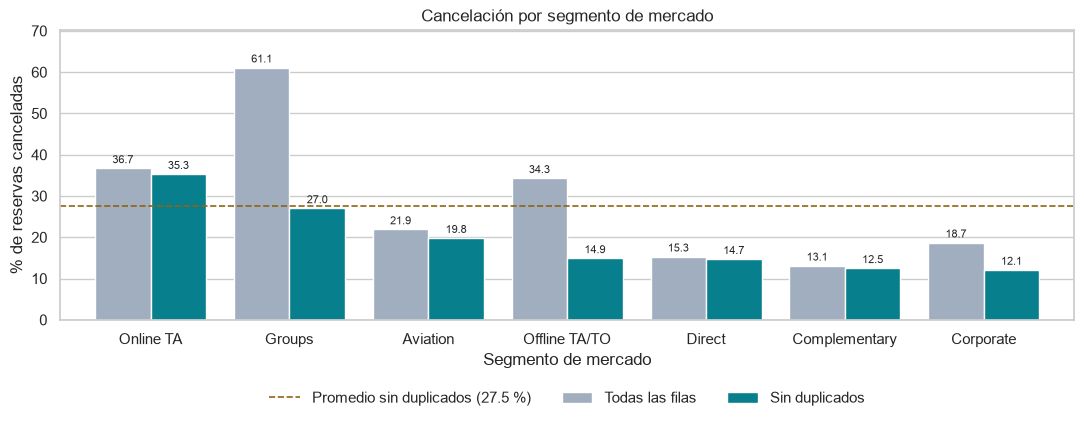

Todas las filas: Online TA tiene el 47.3% de las filas y el 46.9% de las cancelaciones; Groups, el 16.6% y el 27.4%
Sin duplicados: Online TA tiene el 59.1% de las filas y el 75.9% de las cancelaciones; Groups, el 5.7% y el 5.6%
Groups sin duplicados y sin Non Refund: 4,283 filas, cancelan 16.4%


In [29]:
por_segmento = mostrar_tasas(reservas["market_segment"], "Cancelación por segmento de mercado",
                             "Segmento de mercado", ancho=11)

for nombre, base in BASES.items():
    canceladas_base = base[base[OBJETIVO] == 1]
    print(f"{nombre}: Online TA tiene el {(base['market_segment'] == 'Online TA').mean():.1%} de las filas "
          f"y el {(canceladas_base['market_segment'] == 'Online TA').mean():.1%} de las cancelaciones; "
          f"Groups, el {(base['market_segment'] == 'Groups').mean():.1%} y el {(canceladas_base['market_segment'] == 'Groups').mean():.1%}")

grupos_unicos = reservas_unicas[reservas_unicas["market_segment"] == "Groups"]
grupos_sin_non_refund = grupos_unicos[grupos_unicos["deposit_type"] != "Non Refund"]
print(f"Groups sin duplicados y sin Non Refund: {len(grupos_sin_non_refund):,} filas, "
      f"cancelan {grupos_sin_non_refund[OBJETIVO].mean():.1%}")

**¿Qué vemos?**

Aquí es donde más cambia la historia. Con todas las filas el peor segmento de lejos es *Groups* (61,1 %), seguido de *Online TA* (36,7 %) y *Offline TA/TO* (34,3 %). Sin duplicados, *Groups* cae a 27,0 % y *Offline TA/TO* a 14,9 %, mientras que *Online TA* casi ni se mueve (35,3 %) y queda de primero. Si solo hubiéramos mirado la primera base, habríamos concluido que el problema son los grupos.

Y *Online TA* es donde está el volumen: sin duplicados tiene el 59,1 % de las filas y el 75,9 % de las cancelaciones, mientras que *Groups* baja de 27,4 % a 5,6 % de las cancelaciones. Dentro de *Groups* también pesa el depósito: sin duplicados y sin *Non Refund* cancela 16,4 %.

Una explicación posible es que en las agencias en línea cancelar sea fácil y gratis, pero el dataset no trae las condiciones de cada agencia, entonces queda como hipótesis. Lo de *Corporate*, *Direct* y *Complementary*, que cancelan bastante menos, se ve en las dos bases.

,filas_todas,cancelacion_todas_%,filas_unicas,cancelacion_unicas_%,cambio_en_puntos
distribution_channel,,,,,
Undefined,5,80.0,5,80.0,0.0
TA/TO,97870,41.0,69141,31.0,-10.0
GDS,193,19.2,181,19.9,0.7
Direct,14645,17.5,12988,14.8,-2.7
Corporate,6677,22.1,5081,12.8,-9.3


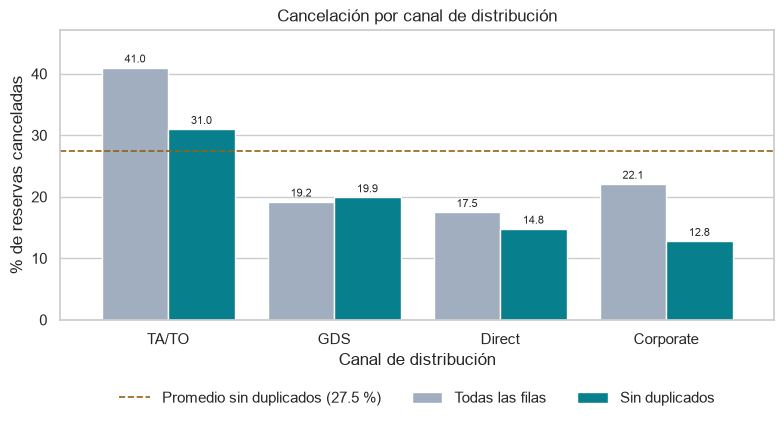

Segmentos dentro del canal TA/TO, sin duplicados (%):
market_segment
Online TA        74.2
Offline TA/TO    19.9
Groups            5.2


In [30]:
por_canal = mostrar_tasas(reservas["distribution_channel"], "Cancelación por canal de distribución",
                          "Canal de distribución", ancho=8)

segmentos_de_ta_to = reservas_unicas.loc[reservas_unicas["distribution_channel"] == "TA/TO", "market_segment"]
print("Segmentos dentro del canal TA/TO, sin duplicados (%):")
print(segmentos_de_ta_to.value_counts(normalize=True).mul(100).round(1).head(3).to_string())

**¿Qué vemos?**

El canal *TA/TO* es el que más cancela en las dos bases (41,0 % y 31,0 %). *Corporate* es el que más baja al quitar las copias, de 22,1 % a 12,8 %, mientras que *Direct* pasa de 17,5 % a 14,8 % y *GDS* se queda en 19,2 % y 19,9 %, con menos de 200 filas. Esta variable es menos fina que el segmento: dentro de *TA/TO* el 74,2 % de las filas es *Online TA* y el 19,9 % es *Offline TA/TO*, que cancelan muy distinto (35,3 % contra 14,9 %). Las dos columnas dicen en buena parte lo mismo, y eso conviene tenerlo en cuenta en la regresión logística, que no se lleva bien con variables redundantes.

,filas_todas,cancelacion_todas_%,filas_unicas,cancelacion_unicas_%,cambio_en_puntos
customer_type,,,,,
Transient,89613,40.7,71986,30.1,-10.6
Contract,4076,31.0,3139,16.3,-14.7
Transient-Party,25124,25.4,11727,15.2,-10.2
Group,577,10.2,544,9.9,-0.3


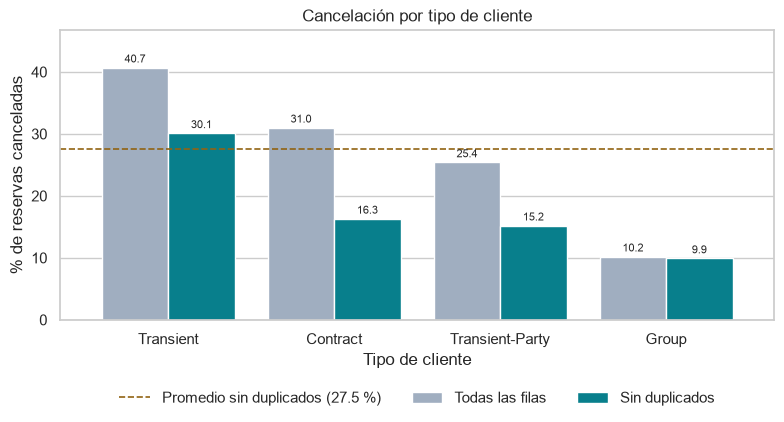

Tipo de cliente dentro de las filas Non Refund (%):
customer_type
Transient          88.5
Transient-Party     7.8
Contract            3.7


In [31]:
por_tipo_cliente = mostrar_tasas(reservas["customer_type"], "Cancelación por tipo de cliente", "Tipo de cliente", ancho=8)

print("Tipo de cliente dentro de las filas Non Refund (%):")
print(reservas.loc[sin_reembolso, "customer_type"].value_counts(normalize=True).mul(100).round(1).to_string())

**¿Qué vemos?**

*Transient*, la reserva suelta, es la que más cancela en las dos bases (40,7 % y 30,1 %), y *Group* la que menos (10,2 % y 9,9 %). *Contract* es el que más baja al quitar las copias, de 31,0 % a 16,3 %. *Transient* y *Transient-Party* bajan unos 10 puntos cada uno.

Ojo con no confundir `customer_type` *Group* con `market_segment` *Groups*, porque miden cosas distintas. El primero tiene solo 577 filas y cancela poco; el segundo tiene 19.811 y cancela mucho más. De hecho, el 88,5 % de las filas *Non Refund*, que parecían bloqueos de agencia, quedaron registradas como *Transient*. O sea que no podemos usar `customer_type` para decir si una reserva era o no de un grupo.

### 3.5 Mes de llegada

En la sección 1 vimos que la demanda sube y baja según el mes y quedó pendiente mirar si las cancelaciones también. Como 2015 y 2017 están incompletos, para comparar años solo usamos julio y agosto, que son los únicos meses que están en los tres.

,filas_todas,cancelacion_todas_%,filas_unicas,cancelacion_unicas_%,cambio_en_puntos
January,5929,30.5,4693,22.1,-8.4
February,8068,33.4,6098,23.2,-10.2
March,9794,32.2,7513,24.4,-7.8
April,11089,40.8,7908,30.5,-10.3
May,11791,39.7,8355,29.2,-10.5
June,10939,41.5,7765,30.3,-11.2
July,12661,37.5,10057,31.8,-5.7
August,13877,37.8,11257,32.2,-5.6
September,10508,39.2,6690,24.5,-14.7
October,11160,38.0,6934,23.7,-14.3


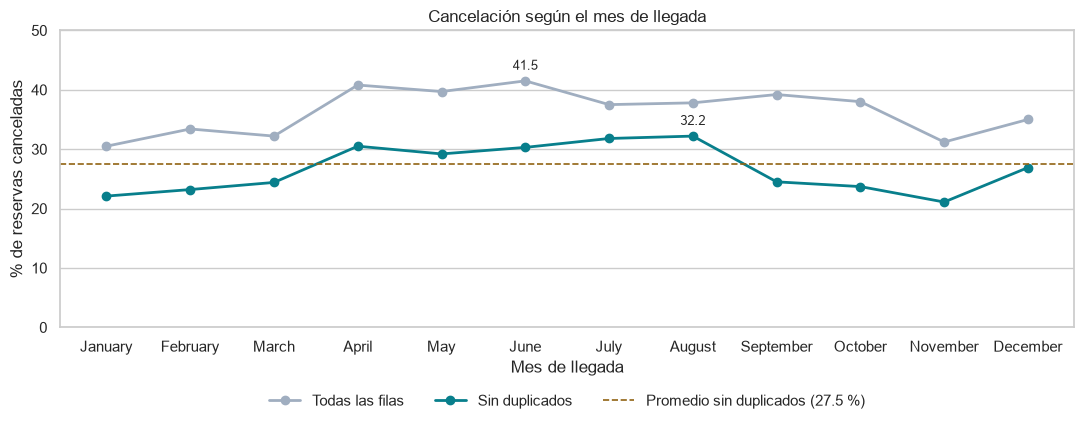

,filas_todas,cancelacion_todas_%,filas_unicas,cancelacion_unicas_%,cambio_en_puntos
arrival_date_year,,,,,
2015,6665,42.9,4127,26.2,-16.7
2016,9635,34.5,8274,30.6,-3.9
2017,10238,37.1,8913,36.0,-1.1


In [32]:
mes_ordenado = pd.Series(pd.Categorical(reservas["arrival_date_month"], categories=MESES, ordered=True),
                         index=reservas.index)
por_mes = tasas_de_cancelacion(mes_ordenado)
display(por_mes)

fig, ax = plt.subplots(figsize=(11, 4.5))
for (columna, nombre), color in zip(COLUMNAS_TASA.items(), COLORES_BASE):
    ax.plot(por_mes.index.astype(str), por_mes[columna], marker="o", linewidth=2, color=color, label=nombre)
    mes_pico = por_mes[columna].idxmax()
    ax.annotate(f"{por_mes.loc[mes_pico, columna]:.1f}", (str(mes_pico), por_mes.loc[mes_pico, columna]),
                textcoords="offset points", xytext=(0, 8), ha="center", fontsize=9)
ax.axhline(TASA_UNICAS, color=COLOR_RIESGO, linestyle="--", linewidth=1.2,
           label=f"Promedio sin duplicados ({TASA_UNICAS:.1f} %)")
ax.set_ylim(0, 50)
ax.grid(axis="x", visible=False)
ax.set_title("Cancelación según el mes de llegada")
ax.set_xlabel("Mes de llegada")
ax.set_ylabel("% de reservas canceladas")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncols=3, frameon=False)
plt.tight_layout()
plt.show()

julio_agosto = reservas["arrival_date_month"].isin(MESES_COMPARABLES)
display(tasas_de_cancelacion(reservas.loc[julio_agosto, "arrival_date_year"]))

**¿Qué vemos?**

Los duplicados también cambian la forma de la temporada. Con todas las filas casi todo el año está alto, con los picos en junio (41,5 %) y abril (40,8 %), y septiembre y octubre siguen en 39,2 % y 38,0 %. Sin duplicados, esos dos meses caen a 24,5 % y 23,7 %, que son las bajas más grandes del año (14,7 y 14,3 puntos), y el pico pasa a agosto (32,2 %) y julio (31,8 %). Lo que coincide en las dos bases es que enero, febrero y noviembre están entre los meses más bajos (22,1 %, 23,2 % y 21,1 % sin duplicados).

El mes se conoce al reservar, entonces puede entrar. Eso sí, solo tenemos un poco más de dos años: no alcanzan para afirmar que esto sea un patrón estacional que se repite.

La comparación de julio y agosto entre años da un resultado incómodo. Con todas las filas la tasa baja de 42,9 % en 2015 a 34,5 % en 2016 y sube a 37,1 % en 2017. Sin duplicados sube todos los años: 26,2 %, 30,6 % y 36,0 %. Según la base, la tendencia es distinta, y además son solo dos meses, así que no la tomamos como conclusión. Lo que sí nos deja es una alerta para la validación temporal del notebook 03: si la cancelación cambia con los años, un modelo entrenado con 2015-2016 se va a encontrar con otra proporción en 2017. Por lo mismo, no nos parece buena idea que `arrival_date_year` entre como variable: un año futuro nunca va a estar en el entrenamiento.

### 3.6 Cancelaciones previas, pedidos especiales y parqueadero

Las tres son conteos con muy pocos valores altos, así que juntamos los valores altos en un solo grupo. El parqueadero lo miramos como sí o no.

,filas_todas,cancelacion_todas_%,filas_unicas,cancelacion_unicas_%,cambio_en_puntos
previous_cancellations,,,,,
0,112906,33.9,85711,26.7,-7.2
1,6051,94.4,1407,76.1,-18.3
2,116,32.8,112,30.4,-2.4
3 o más,317,59.9,166,23.5,-36.4


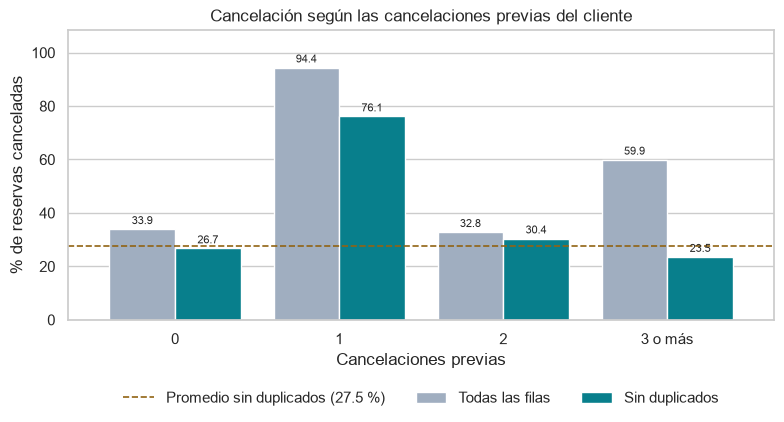

Filas con alguna cancelación previa: 6,484 con todas las filas y 1,685 sin duplicados
De ellas son Non Refund: 56.2% con todas las filas y 12.8% sin duplicados


In [33]:
por_previas = mostrar_tasas(agrupar_conteo(reservas["previous_cancellations"]),
                            "Cancelación según las cancelaciones previas del cliente",
                            "Cancelaciones previas", ordenar=False, ancho=8)

con_previas = reservas["previous_cancellations"] > 0
print(f"Filas con alguna cancelación previa: {con_previas.sum():,} con todas las filas y {con_previas[~duplicadas].sum():,} sin duplicados")
print(f"De ellas son Non Refund: {sin_reembolso[con_previas].mean():.1%} con todas las filas "
      f"y {sin_reembolso[con_previas & ~duplicadas].mean():.1%} sin duplicados")

**¿Qué vemos?**

Quien tiene exactamente una cancelación previa cancela muchísimo: 94,4 % con todas las filas y 76,1 % sin duplicados, frente a 33,9 % y 26,7 % de quien no tiene ninguna. Pero la relación no es "entre más cancelaciones, peor". Con dos previas baja a 32,8 % y 30,4 %, y con tres o más queda en 59,9 % con todas las filas y 23,5 % sin duplicados.

Esa rareza tiene que ver con las copias: el 56,2 % de las filas con alguna cancelación previa son *Non Refund*, y sin duplicados solo el 12,8 %. Además quedan pocas: de 6.484 filas pasamos a 1.685. Por eso la variable pierde fuerza, aunque sigue aportando. Un indicador de "tuvo cancelaciones previas", que suena lógico como variable derivada, mezclaría el 76,1 % de los que tienen una con el 30,4 % de los que tienen dos; toca revisar si conviene dejarla como conteo.

Se conoce al reservar, porque es el historial del cliente hasta ese momento. Como no hay identificador de cliente, no podemos revisar cómo se calculó.

,filas_todas,cancelacion_todas_%,filas_unicas,cancelacion_unicas_%,cambio_en_puntos
total_of_special_requests,,,,,
0,70318,47.7,43894,33.2,-14.5
1,33226,22.0,29017,22.4,0.4
2,12969,22.1,11812,21.3,-0.8
3 o más,2877,16.8,2673,16.2,-0.6


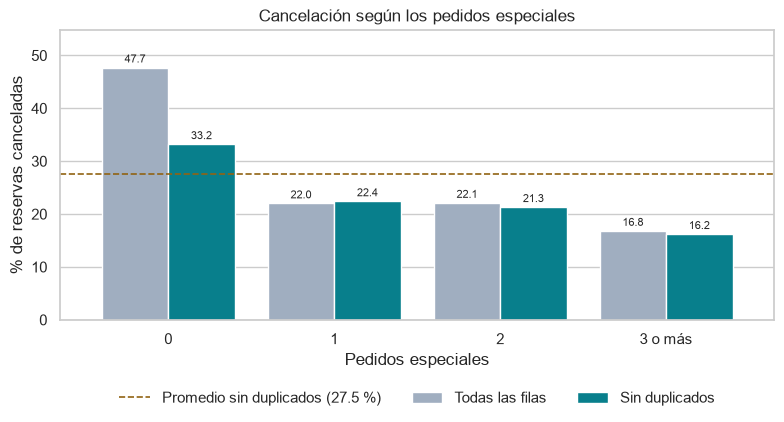

Solo Online TA, sin duplicados: 52.9% sin pedidos y 25.4% con al menos uno


In [34]:
por_pedidos = mostrar_tasas(agrupar_conteo(reservas["total_of_special_requests"]),
                            "Cancelación según los pedidos especiales",
                            "Pedidos especiales", ordenar=False, ancho=8)

online_unicas = reservas_unicas[reservas_unicas["market_segment"] == "Online TA"]
sin_pedidos_online = online_unicas["total_of_special_requests"] == 0
print(f"Solo Online TA, sin duplicados: {online_unicas.loc[sin_pedidos_online, OBJETIVO].mean():.1%} sin pedidos "
      f"y {online_unicas.loc[~sin_pedidos_online, OBJETIVO].mean():.1%} con al menos uno")

**¿Qué vemos?**

El salto está entre no pedir nada y pedir algo: sin pedidos cancela 47,7 % con todas las filas y 33,2 % sin duplicados, y con un pedido ya baja a 22,0 % y 22,4 %. Después sigue bajando despacio (16,2 % con tres o más sin duplicados, y son pocas filas).

La diferencia se reduce sin duplicados porque los bloqueos de agencia casi nunca traen pedidos. Pero no es solo eso: mirando únicamente *Online TA* sin duplicados, las reservas sin pedidos cancelan 52,9 % y las que tienen al menos uno, 25,4 %. Tiene sentido que quien pide una cama doble o un piso alto esté más decidido a llegar.

Le queda una duda: un pedido se puede agregar días después de reservar, y el dataset no dice cuándo se hizo. No la dejamos por fuera porque ningún valor da una tasa perfecta y la variable tiene una explicación razonable, pero en la importancia de variables del notebook 03 hay que mirarla con cuidado.

,filas_todas,cancelacion_todas_%,filas_unicas,cancelacion_unicas_%,cambio_en_puntos
required_car_parking_spaces,,,,,
Sin parqueadero,111974,39.5,80083,30.0,-9.5
Con parqueadero,7416,0.0,7313,0.0,0.0


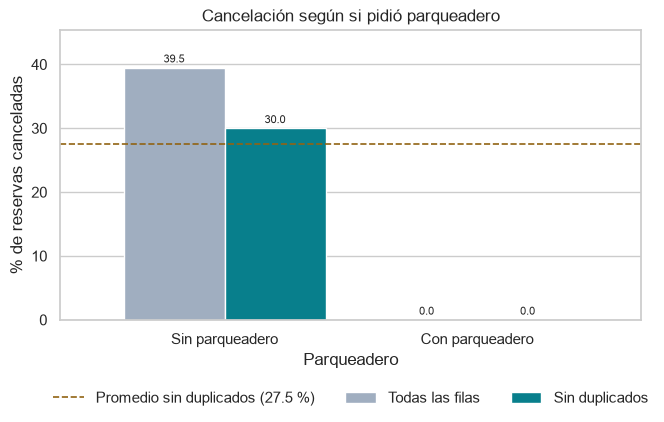

Sin duplicados: 7,313 reservas con parqueadero y 0 canceladas
Si cancelaran como las demás serían unas 2,194
Último estado: {'Check-Out': 7313}
Por hotel: {'Resort Hotel': 5417, 'City Hotel': 1896}


In [35]:
con_parqueadero = reservas["required_car_parking_spaces"] > 0
grupos_parqueadero = con_parqueadero.map({True: "Con parqueadero", False: "Sin parqueadero"})
por_parqueadero = mostrar_tasas(grupos_parqueadero, "Cancelación según si pidió parqueadero", "Parqueadero", ancho=7)

parqueadero_unicas = reservas_unicas[reservas_unicas["required_car_parking_spaces"] > 0]
tasa_sin_parqueadero = reservas_unicas.loc[reservas_unicas["required_car_parking_spaces"] == 0, OBJETIVO].mean()
print(f"Sin duplicados: {len(parqueadero_unicas):,} reservas con parqueadero y {parqueadero_unicas[OBJETIVO].sum()} canceladas")
print(f"Si cancelaran como las demás serían unas {len(parqueadero_unicas) * tasa_sin_parqueadero:,.0f}")
print("Último estado:", parqueadero_unicas["reservation_status"].value_counts().to_dict())
print("Por hotel:", parqueadero_unicas["hotel"].value_counts().to_dict())

**¿Qué vemos?**

Ninguna de las reservas con parqueadero se canceló: 0 de 7.416 con todas las filas y 0 de 7.313 sin duplicados, en los dos hoteles. Si cancelaran como las demás serían unas 2.194, así que el resultado es demasiado perfecto para tomarlo como comportamiento de los clientes.

Pueden ser clientes muy comprometidos, pero nos parece más probable que el parqueadero se anote cuando el cliente llega, o que quede registrado solo si la reserva terminó en estadía. Como dijimos en la 1.4, no sabemos en qué momento se llena cada campo. Si es así, tiene el mismo problema de `assigned_room_type`: un modelo le daría muchísimo peso y en producción, cuando entra una reserva nueva, ese dato todavía no existiría. Al arrancar no la teníamos en la lista de sospechosas, pero con esta evidencia la sumamos a la discusión de fuga de la 3.8.

### 3.7 Correlaciones

Miramos las variables numéricas, primero entre ellas y después con la cancelación. Usamos la correlación de Spearman en vez de la de Pearson porque trabaja con el orden de los valores: como en la 2.5 vimos colas largas y atípicos, y varias de estas variables son conteos, Pearson se dejaría mover por unos pocos valores extremos. Dejamos por fuera `agent` y `company`, que son códigos, y el año, que ya revisamos.

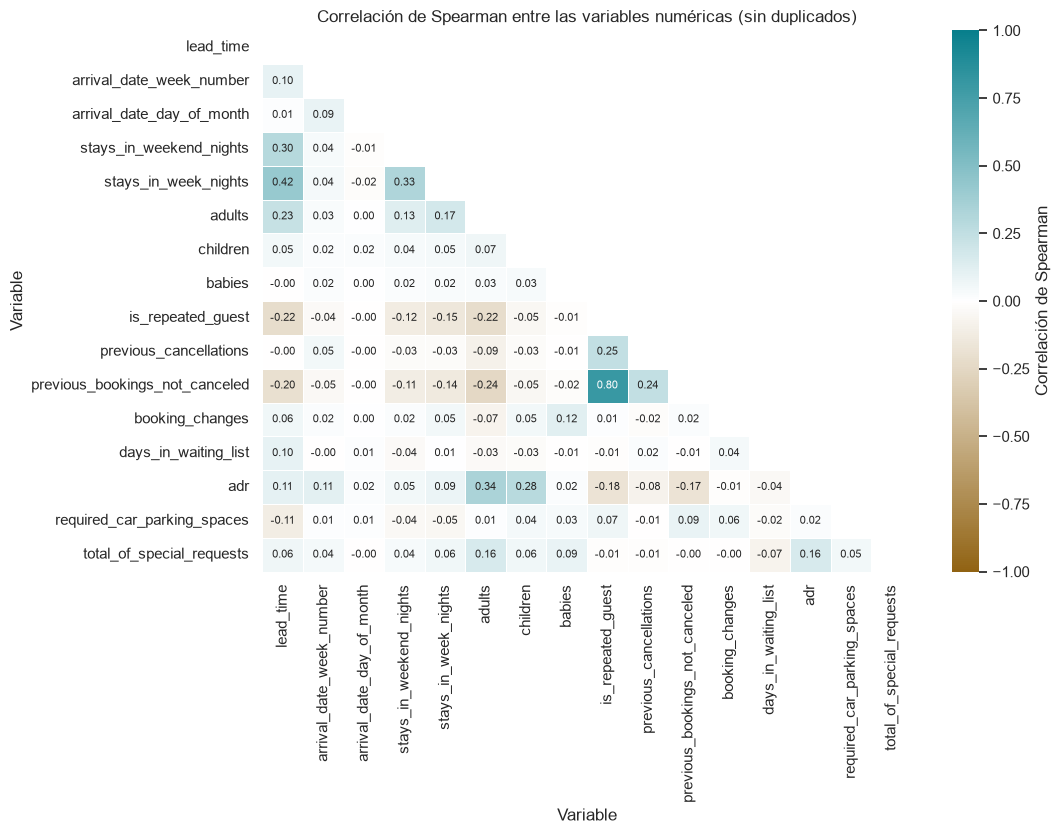

Pares más correlacionados:
is_repeated_guest        previous_bookings_not_canceled    0.797
lead_time                stays_in_week_nights              0.418
adults                   adr                               0.340
stays_in_weekend_nights  stays_in_week_nights              0.327
lead_time                stays_in_weekend_nights           0.295


In [36]:
VARIABLES_NUMERICAS = [
    "lead_time", "arrival_date_week_number", "arrival_date_day_of_month",
    "stays_in_weekend_nights", "stays_in_week_nights", "adults", "children", "babies",
    "is_repeated_guest", "previous_cancellations", "previous_bookings_not_canceled",
    "booking_changes", "days_in_waiting_list", "adr",
    "required_car_parking_spaces", "total_of_special_requests",
]

correlaciones = reservas_unicas[VARIABLES_NUMERICAS].corr(method="spearman")
triangulo_superior = np.triu(np.ones(correlaciones.shape, dtype=bool))
mapa_de_color = LinearSegmentedColormap.from_list("riesgo_a_principal", [COLOR_RIESGO, "white", COLOR_PRINCIPAL])

fig, ax = plt.subplots(figsize=(11, 8.5))
sns.heatmap(correlaciones, mask=triangulo_superior, cmap=mapa_de_color, vmin=-1, vmax=1,
            annot=True, fmt=".2f", annot_kws={"size": 8}, linewidths=0.5,
            cbar_kws={"label": "Correlación de Spearman"}, ax=ax)
ax.grid(False)
ax.set_title("Correlación de Spearman entre las variables numéricas (sin duplicados)")
ax.set_xlabel("Variable")
ax.set_ylabel("Variable")
plt.tight_layout()
plt.show()

pares = correlaciones.where(~triangulo_superior.T).stack()
print("Pares más correlacionados:")
print(pares.reindex(pares.abs().sort_values(ascending=False).index).head(5).round(3).to_string())

**¿Qué vemos?**

Casi todo el mapa está claro, o sea que las numéricas no se repiten mucho entre sí. La excepción es `is_repeated_guest` con `previous_bookings_not_canceled` (0,797), y es lógico: el que ya ha ido al hotel tiene reservas anteriores. Eso es lo que hay que vigilar en la regresión logística por la multicolinealidad. Le siguen `lead_time` con `stays_in_week_nights` (0,418), `adults` con `adr` (0,340, más personas pagan una habitación más cara) y las noches de semana con las de fin de semana (0,327), todas moderadas o bajas.

In [37]:
correlacion_con_objetivo = pd.DataFrame({
    nombre: base[VARIABLES_NUMERICAS].corrwith(base[OBJETIVO], method="spearman").round(3)
    for nombre, base in BASES.items()
}).sort_values("Sin duplicados", key=abs, ascending=False)
display(correlacion_con_objetivo)

print(f"Tarifa mediana: {reservas.loc[duplicadas, 'adr'].median():.1f} en las filas repetidas "
      f"y {reservas_unicas['adr'].median():.1f} sin duplicados")

,Todas las filas,Sin duplicados
lead_time,0.317,0.226
required_car_parking_spaces,-0.197,-0.186
adr,0.051,0.143
total_of_special_requests,-0.259,-0.128
previous_cancellations,0.270,0.126
booking_changes,-0.185,-0.125
previous_bookings_not_canceled,-0.115,-0.104
stays_in_week_nights,0.041,0.096
adults,0.067,0.091
is_repeated_guest,-0.085,-0.090


Tarifa mediana: 85.9 en las filas repetidas y 98.1 sin duplicados


**¿Qué vemos?**

Ninguna variable numérica tiene una correlación fuerte con la cancelación: la más alta es `lead_time`, con 0,317 con todas las filas y 0,226 sin duplicados. Varias pierden bastante al quitar las copias: `previous_cancellations` baja de 0,270 a 0,126, `total_of_special_requests` de −0,259 a −0,128 y `days_in_waiting_list` de 0,098 a 0,015, que ya es casi nada. La tarifa va al revés: `adr` sube de 0,051 a 0,143. Puede ser porque las copias tienen una tarifa mediana más baja (85,9 contra 98,1) y cancelan mucho, lo que tapaba la relación.

Estos valores bajos no quieren decir que estas variables no sirvan para predecir. Spearman solo capta relaciones que van siempre en la misma dirección, y ya vimos que `previous_cancellations` sube y baja. Tampoco entran aquí `deposit_type` ni `market_segment`, que son categóricas y están entre las que más separan. Por eso tiene sentido comparar con un modelo que capte relaciones no lineales, como la SVM con kernel RBF del notebook 03. Correlación tampoco es causa: una anticipación larga no obliga a nadie a cancelar.

### 3.8 Variables con fuga de información

La regla que acordamos es que una variable solo entra si se conoce en el momento de hacer la reserva. Una columna con fuga es peligrosa porque mejora las métricas sin que el modelo sirva para nada en la práctica: cuando entra una reserva nueva, ese dato todavía no existe.

Primero revisamos las cuatro columnas que ya sospechábamos: `reservation_status`, `reservation_status_date`, `assigned_room_type` y `booking_changes`.

In [38]:
display(pd.crosstab(reservas["reservation_status"], reservas[OBJETIVO]))

fecha_del_estado = pd.to_datetime(reservas["reservation_status_date"])
dias_desde_llegada = (fecha_del_estado - llegada).dt.days
es_cancelada = reservas[OBJETIVO] == 1
fecha_no_cuadra = dias_desde_llegada != total_noches

print(f"No canceladas cuyo estado cae justo el día de salida: {(~fecha_no_cuadra)[~es_cancelada].mean():.2%}")
print(f"Canceladas con el estado antes de la llegada: {(dias_desde_llegada[es_cancelada] < 0).mean():.1%}; "
      f"después de la llegada: {(dias_desde_llegada[es_cancelada] > 0).sum()}")
print(f"Acierto de la regla 'la fecha no es llegada + noches, entonces se canceló': "
      f"{(fecha_no_cuadra == es_cancelada).mean():.2%} con todas las filas y "
      f"{(fecha_no_cuadra == es_cancelada)[~duplicadas].mean():.2%} sin duplicados")

is_canceled,0,1
reservation_status,,
Canceled,0,43017
Check-Out,75166,0
No-Show,0,1207


No canceladas cuyo estado cae justo el día de salida: 99.96%
Canceladas con el estado antes de la llegada: 95.3%; después de la llegada: 0
Acierto de la regla 'la fecha no es llegada + noches, entonces se canceló': 99.95% con todas las filas y 99.94% sin duplicados


In [39]:
habitacion_distinta = (reservas["assigned_room_type"] != reservas["reserved_room_type"]).map(
    {True: "Asignada distinta de la reservada", False: "Asignada igual a la reservada"})
display(tasas_de_cancelacion(habitacion_distinta))
display(tasas_de_cancelacion(agrupar_conteo(reservas["booking_changes"]).rename("booking_changes")))

,filas_todas,cancelacion_todas_%,filas_unicas,cancelacion_unicas_%,cambio_en_puntos
Asignada distinta de la reservada,14917,5.4,13109,4.7,-0.7
Asignada igual a la reservada,104473,41.6,74287,31.5,-10.1


,filas_todas,cancelacion_todas_%,filas_unicas,cancelacion_unicas_%,cambio_en_puntos
booking_changes,,,,,
0,101314,40.9,71494,30.2,-10.7
1,12701,14.2,10902,13.9,-0.3
2,3805,20.1,3508,20.1,0.0
3 o más,1570,16.6,1492,16.2,-0.4


**¿Qué vemos?**

`reservation_status` es la respuesta escrita de otra forma: todas las *Canceled* (43.017) y *No-Show* (1.207) tienen `is_canceled` en 1 y todos los *Check-Out* (75.166) en 0. Si entra, el modelo no tiene nada que aprender.

`reservation_status_date` también la delata, aunque cuesta más verlo. En las reservas no canceladas, esa fecha cae justo el día de salida (llegada más noches) en el 99,96 % de los casos, y en las canceladas nunca es posterior a la llegada. Con solo esa resta, sin ningún modelo, acertamos el 99,95 % de las filas, o el 99,94 % sin duplicados.

`assigned_room_type` se decide cerca de la llegada. Cuando la habitación asignada es distinta de la reservada, solo cancela 5,4 % (4,7 % sin duplicados) contra 41,6 % (31,5 %) cuando es igual. Lo que pasa, muy probablemente, es que el cambio se le hace a quien ya está llegando; a una reserva que se canceló meses antes nadie le reasigna habitación. O sea que la flecha va al revés de lo que le serviría al modelo.

`booking_changes` se va llenando hasta el check-in o la cancelación. Sin cambios cancela 40,9 % con todas las filas y 30,2 % sin duplicados, y con algún cambio esa tasa es mucho menor. Es la menos obvia de las cuatro, porque un cliente sí puede cambiar algo temprano. Pero el valor que se ve aquí es el conteo final, y al momento de reservar siempre es cero.

Las cuatro dan lo mismo en las dos bases: quitar duplicados no arregla la fuga. Por eso se confirman por fuera.

Faltaban dos por decidir: `country` y `days_in_waiting_list`. Empezamos por el país, con lo de Portugal.

In [40]:
es_portugal = reservas["country"].eq("PRT").map({True: "Portugal", False: "Otros países o sin país"})
display(tasas_de_cancelacion(es_portugal))

display(pd.DataFrame({
    nombre: base.groupby("reservation_status")["country"].apply(lambda paises: paises.eq("PRT").mean() * 100).round(1)
    for nombre, base in BASES.items()
}).rename_axis("% de Portugal según el último estado"))

print("Reservas sin país, por último estado:", reservas.loc[reservas["country"].isna(), "reservation_status"].value_counts().to_dict())

,filas_todas,cancelacion_todas_%,filas_unicas,cancelacion_unicas_%,cambio_en_puntos
country,,,,,
Otros países o sin país,70800,23.6,59943,23.7,0.1
Portugal,48590,56.6,27453,35.7,-20.9


,Todas las filas,Sin duplicados
% de Portugal según el último estado,,
Canceled,62.2,39.9
Check-Out,28.0,27.9
No-Show,63.2,60.0


Reservas sin país, por último estado: {'Check-Out': 421, 'Canceled': 63, 'No-Show': 4}


**¿Qué vemos?**

Sin duplicados la diferencia se reduce mucho, pero no desaparece. Con todas las filas Portugal cancela 56,6 % contra 23,6 % del resto (33 puntos) y sin duplicados 35,7 % contra 23,7 % (12 puntos). Buena parte de la brecha venía de los bloqueos *Non Refund*, que casi todos están registrados como Portugal.

Lo que queda se puede leer de dos maneras: que los portugueses de verdad cancelen más, o que el país no se conozca bien al reservar y se corrija en el check-in. La tabla del último estado apunta a lo segundo. Sin duplicados, Portugal es el 27,9 % de los *Check-Out*, el 39,9 % de las canceladas y el 60,0 % de los *No-Show*, que son justo los clientes que nunca pasaron por la recepción.

También revisamos lo que dejamos planteado en la 2.1 sobre los vacíos, y eso no se sostiene: de las 488 reservas sin país, 421 terminaron en *Check-Out*. O sea que el vacío no marca a las que no llegaron. Si hay fuga, va por otro lado: que Portugal quede como valor inicial y se cambie cuando el cliente llega. Para probarlo comparamos dentro de cada segmento, sin *Non Refund* para que esos bloqueos no enreden la comparación.

country,Otros países o sin país,Portugal,filas Otros países o sin país,filas Portugal
market_segment,,,,
Online TA,33.1,43.3,40500,11100
Groups,0.8,42.5,2677,1606
Offline TA/TO,0.5,39.7,9237,4365
Direct,10.7,19.2,6302,5492
Corporate,3.0,13.7,972,3176


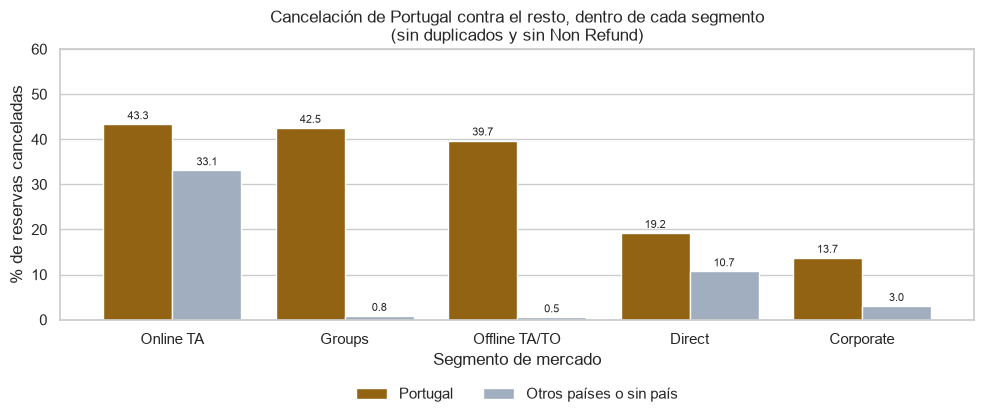

market_segment,Online TA,Offline TA/TO,Groups
country,,,
PRT,43.3,39.7,42.5
GBR,32.3,0.2,0.9
FRA,27.7,0.2,2.3
ESP,35.2,0.3,0.7
DEU,28.4,0.1,0.0


In [41]:
sin_non_refund = reservas_unicas[~es_non_refund_unica]
origen = sin_non_refund["country"].eq("PRT").map({True: "Portugal", False: "Otros países o sin país"})

cancelacion_por_origen = (
    sin_non_refund.groupby(["market_segment", origen])[OBJETIVO]
    .agg(filas="size", cancelacion="mean")
    .unstack()
)
suficientes = cancelacion_por_origen["filas"].min(axis=1) >= MINIMO_FILAS_SEGMENTO
tabla_origen = (cancelacion_por_origen.loc[suficientes, "cancelacion"] * 100).round(1)
tabla_origen = tabla_origen.sort_values("Portugal", ascending=False)
display(tabla_origen.join(cancelacion_por_origen.loc[suficientes, "filas"].astype(int).add_prefix("filas ")))

fig, ax = plt.subplots(figsize=(10, 4.5))
tabla_origen[["Portugal", "Otros países o sin país"]].plot.bar(
    ax=ax, color=[COLOR_RIESGO, COLOR_SECUNDARIO], width=0.8, edgecolor="white")
for barras in ax.containers:
    ax.bar_label(barras, fmt="%.1f", fontsize=8, padding=2)
ax.set_ylim(0, 60)
ax.grid(axis="x", visible=False)
ax.set_title("Cancelación de Portugal contra el resto, dentro de cada segmento\n(sin duplicados y sin Non Refund)")
ax.set_xlabel("Segmento de mercado")
ax.set_ylabel("% de reservas canceladas")
ax.tick_params(axis="x", rotation=0)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncols=2, frameon=False)
plt.tight_layout()
plt.show()

por_pais = sin_non_refund[sin_non_refund["country"].isin(PAISES_COMPARAR)
                          & sin_non_refund["market_segment"].isin(SEGMENTOS_COMPARAR)]
por_pais.pivot_table(index="country", columns="market_segment", values=OBJETIVO, aggfunc="mean").mul(100).round(1).loc[
    PAISES_COMPARAR, SEGMENTOS_COMPARAR]

**¿Qué vemos?**

Esta es la evidencia más fuerte. En *Offline TA/TO* cancela 39,7 % de las reservas de Portugal y 0,5 % de las demás. En *Groups*, 42,5 % contra 0,8 %. Una tasa de cancelación casi en cero para todo el resto del mundo no es creíble como comportamiento de los clientes, y la última tabla lo confirma: los británicos cancelan 32,3 % cuando reservan por *Online TA* y 0,2 % por *Offline TA/TO*; los franceses, 27,7 % y 0,2 %; los alemanes, 28,4 % y 0,1 %.

En cambio en *Online TA* la distancia es mucho menor (43,3 % contra 33,1 %), y tiene sentido: en una página web el mismo cliente escribe sus datos al reservar. Cuando la reserva la mete una agencia sin los datos de cada huésped, todo cuadra con lo siguiente: el país queda como Portugal y se corrige en la recepción. Entonces, en esos canales, tener un país distinto de Portugal significa, en la práctica, que el cliente ya llegó.

No lo podemos demostrar del todo, porque no tenemos el registro de cuándo se llenó el campo. Podría haber otra explicación, como agencias portuguesas que cancelan mucho más y que registran sus reservas como Portugal. Igual no hace falta probarlo para decidir: una variable entra si sabemos que se conoce al reservar, y aquí no lo sabemos y además todo apunta a que no. Recomendamos que **`country` no entre** al modelo. El costo es perder una variable que probablemente subiría las métricas, pero justamente esa mejora no sería real.

Esto también le quita presión a la alta cardinalidad: de las tres columnas de la 2.6, ya solo quedaría `agent` por codificar.

Queda `days_in_waiting_list`.

In [42]:
estuvo_en_espera = (reservas["days_in_waiting_list"] > 0).map({True: "Estuvo en lista de espera", False: "No estuvo"})
display(tasas_de_cancelacion(estuvo_en_espera))

dias_en_espera = pd.cut(reservas["days_in_waiting_list"], bins=CORTES_ESPERA, labels=ETIQUETAS_ESPERA)
display(tasas_de_cancelacion(dias_en_espera))

en_espera_unicas = reservas_unicas[reservas_unicas["days_in_waiting_list"] > 0]
en_espera_sin_non_refund = en_espera_unicas[en_espera_unicas["deposit_type"] != "Non Refund"]
print(f"Sin duplicados y sin Non Refund: {len(en_espera_sin_non_refund):,} filas en espera, "
      f"cancelan {en_espera_sin_non_refund[OBJETIVO].mean():.1%}")
print(f"Filas con más días de espera que de anticipación: {(reservas['days_in_waiting_list'] > reservas['lead_time']).sum()}")

,filas_todas,cancelacion_todas_%,filas_unicas,cancelacion_unicas_%,cambio_en_puntos
days_in_waiting_list,,,,,
Estuvo en lista de espera,3698,63.8,860,34.2,-29.6
No estuvo,115692,36.2,86536,27.4,-8.8


,filas_todas,cancelacion_todas_%,filas_unicas,cancelacion_unicas_%,cambio_en_puntos
days_in_waiting_list,,,,,
0,115692,36.2,86536,27.4,-8.8
1 a 30,592,75.5,199,43.7,-31.8
31 a 60,1524,69.8,245,40.4,-29.4
61 a 100,835,57.1,210,27.6,-29.5
Más de 100,747,49.8,206,24.3,-25.5


Sin duplicados y sin Non Refund: 652 filas en espera, cancelan 13.3%
Filas con más días de espera que de anticipación: 0


**¿Qué vemos?**

Con todas las filas parecía una variable fuerte: las reservas que pasaron por lista de espera cancelan 63,8 % contra 36,2 %. Sin duplicados casi todo se desinfla: quedan 860 filas (de 3.698) y cancelan 34,2 % contra 27,4 %. Y si además quitamos *Non Refund*, las 652 filas que quedan cancelan 13,3 %, por debajo del promedio. O sea que lo que se veía era sobre todo el efecto de los bloqueos, y por eso la correlación de la 3.7 bajó a 0,015.

Por el lado de la regla tampoco pasa. Esta columna cuenta los días que la reserva esperó antes de que se la confirmaran, y nunca supera a `lead_time`, lo que cuadra con que esos días corran después de hacer la reserva. Entonces, en el momento en que la reserva entra, ese contador todavía no tiene su valor final. Recomendamos que **`days_in_waiting_list` no entre**: no cumple la regla y aporta muy poco.

La tabla con todo lo que revisamos:

| Variable | ¿Se conoce al reservar? | Evidencia | Recomendación |
|---|---|---|---|
| `reservation_status` | No | Coincide 100 % con `is_canceled` | No entra |
| `reservation_status_date` | No | Con una resta se acierta el 99,95 % | No entra |
| `assigned_room_type` | No | Distinta de la reservada: cancela 5,4 % contra 41,6 % | No entra |
| `booking_changes` | No, es el conteo final | Sin cambios: cancela 40,9 %; con cambios, mucho menos | No entra |
| `country` | No lo sabemos, y parece que no | *Offline TA/TO*: 39,7 % Portugal contra 0,5 % el resto | No entra |
| `days_in_waiting_list` | No | Sin duplicados casi no separa (34,2 % contra 27,4 %) | No entra |
| `required_car_parking_spaces` | No lo sabemos, y parece que no | 0 canceladas de 7.313, cuando se esperarían unas 2.194 | Proponemos que no entre al modelo supervisado |
| `total_of_special_requests` | Puede cambiar después | Separa, pero sin valores perfectos | Entra, y se revisa su importancia |
| `deposit_type` | Sí | 94,7 % sin duplicados, pero parece marcar bloqueos | Entra, sin leerlo como causa |

El parqueadero también le importa al agrupamiento del notebook 04: si un segmento se arma alrededor de esta variable, va a salir con una cancelación de casi cero por cómo se llena el dato, y no porque ese perfil de cliente sea especial.

### 3.9 Los duplicados cuando salen las columnas con fuga

Hay un detalle que conecta esta sección con la 2.3. Las 31.994 filas repetidas se contaron con las 32 columnas, incluidas las que acabamos de sacar. Si dos reservas solo se diferenciaban en una de esas columnas, al quitarla quedan idénticas otra vez. Medimos cuántas son.

In [43]:
COLUMNAS_CON_FUGA = ["reservation_status", "reservation_status_date", "assigned_room_type", "booking_changes"]
COLUMNAS_PROPUESTAS = ["country", "days_in_waiting_list", "required_car_parking_spaces"]


def duplicados_sin_columnas(columnas_fuera):
    """Duplicados que quedan al sacar columnas, y filas únicas que se vuelven iguales."""
    columnas = [columna for columna in reservas.columns if columna not in columnas_fuera]
    entradas = [columna for columna in columnas if columna != OBJETIVO]
    repetidas = reservas.duplicated(subset=columnas)
    resultado_por_combinacion = reservas.groupby(entradas, dropna=False)[OBJETIVO].nunique()
    return {
        "columnas": len(columnas),
        "filas_repetidas": repetidas.sum(),
        "filas_que_quedan": (~repetidas).sum(),
        "cancelacion_que_queda_%": round(reservas.loc[~repetidas, OBJETIVO].mean() * 100, 1),
        "unicas_que_vuelven_a_ser_iguales": reservas_unicas.duplicated(subset=entradas).sum(),
        "mismas_entradas_con_distinto_resultado": (resultado_por_combinacion > 1).sum(),
    }


pd.DataFrame.from_dict({
    "Las 32 columnas": duplicados_sin_columnas([]),
    "Sin las 4 con fuga": duplicados_sin_columnas(COLUMNAS_CON_FUGA),
    "Sin esas 4 y sin las 3 propuestas": duplicados_sin_columnas(COLUMNAS_CON_FUGA + COLUMNAS_PROPUESTAS),
}, orient="index")

,columnas,filas_repetidas,filas_que_quedan,cancelacion_que_queda_%,unicas_que_vuelven_a_ser_iguales,mismas_entradas_con_distinto_resultado
Las 32 columnas,32,31994,87396,27.5,0,0
Sin las 4 con fuga,28,34050,85340,27.7,2357,301
Sin esas 4 y sin las 3 propuestas,25,36233,83157,28.3,4826,587


**¿Qué vemos?**

Si quitamos los duplicados con las 32 columnas y después sacamos las variables, 2.357 filas de `reservas_unicas` vuelven a ser iguales en lo que ve el modelo, o 4.826 si salen también las tres que propusimos. Esas filas pueden caer una en entrenamiento y otra en prueba, que es justo lo que queríamos evitar. Por eso, para el notebook 02, recomendamos sacar primero las columnas que no entran y quitar los duplicados después. Cambiar `company` por `tiene_empresa` puede subir esta cuenta, así que el número final depende de las columnas que queden.

Ese orden mueve un poco la tasa: la cancelación queda en 28,3 % y no en 27,5 %, con 83.157 filas. Por eso el notebook 02 tiene que reportar la tasa que le dé y no copiar la nuestra. Además aparecen 587 combinaciones con exactamente las mismas entradas y distinto resultado, en las que una reserva se canceló y la otra no. Ahí ningún modelo puede acertar las dos. Son pocas frente al total, así que el efecto en las métricas debería ser pequeño.

### 3.10 Cierre de la sección

| Hallazgo | Todas las filas | Sin duplicados | Cómo lo leemos |
|---|---|---|---|
| Cancelación general | 37,0 % | 27,5 % | El primero se parece más a lo que pierde el hotel si las copias son reales; el segundo es lo que verá el modelo |
| City Hotel contra Resort Hotel | 41,7 % y 27,8 % | 30,0 % y 23,5 % | Se mantiene, con menos de la mitad de la diferencia |
| Anticipación de 0 a 7 días contra más de 365 | 9,6 % y 67,7 % | 8,4 % y 40,9 % | Firme: más anticipación, más cancelación |
| *Non Refund* | 99,4 % (14.587 filas) | 94,7 % (1.038 filas) | Se mantiene la tasa y cae el peso. Parece marcar bloqueos de agencia |
| *Groups* | 61,1 % | 27,0 % | Cambia mucho: buena parte era efecto de las copias |
| *Online TA* | 36,7 % | 35,3 % | Firme, y sin duplicados es el segmento que más cancela |
| Una cancelación previa | 94,4 % | 76,1 % | Se mantiene alta, con menos filas |
| Sin pedidos especiales | 47,7 % | 33,2 % | Se mantiene |
| Con parqueadero | 0 % | 0 % | Demasiado perfecto: sospecha de fuga |
| Portugal contra el resto | 56,6 % y 23,6 % | 35,7 % y 23,7 % | Se reduce, pero por segmento apunta a fuga |
| Con lista de espera contra sin ella | 63,8 % y 36,2 % | 34,2 % y 27,4 % | Casi todo venía de los bloqueos |

Quitar los duplicados sí cambia las conclusiones, y no solo el promedio. Algunas se sostienen en las dos bases (anticipación, *Online TA*, pedidos especiales) y son las que más confianza nos dan. Otras dependen casi por completo de las copias (*Groups*, lista de espera, el pico de septiembre y octubre) y no las daríamos por hecho.

Lo que le dejamos al notebook 02: quitar las siete columnas de la tabla de la 3.8 que recomendamos dejar por fuera, quitar los duplicados después de sacarlas y reportar la tasa que resulte.

Lo que este análisis no permite concluir: todo lo anterior son asociaciones de dos hoteles de Portugal entre 2015 y 2017, y no causas. No sabemos si las copias son errores o habitaciones reales, y las sospechas de fuga de `country` y del parqueadero salen de cómo se comportan los datos, sin haber podido confirmarlas con el hotel. Con esas limitaciones, los hallazgos sirven para escoger variables y para plantear hipótesis, pero no todavía para decidir políticas del hotel.